### IMPORTING LIBRARY

In [2]:
import os
import random
import datetime
import json
import h5py
import pacmap
import pandas                   as pd
import numpy                    as np
import plotly.express           as px
import plotly.graph_objects     as go

import matplotlib.pyplot        as plt

from tqdm                       import tqdm
from preProcessingData          import PreProcessData
from utility.matpilotDraw       import MatPlot
from utility.plotloyDraw        import PlotlyDraw
from prettytable                import PrettyTable
from model.vaeConv1DCustom      import vaeConv1DCustom 
from vaeTrainer                 import appVAE
from mpl_toolkits.mplot3d       import Axes3D
# from sklearn.cluster            import KMeans
# from sklearn.cluster            import DBSCAN
from sklearn.preprocessing      import StandardScaler, MinMaxScaler
from matplotlib.colors          import Normalize
from sklearn.mixture            import GaussianMixture



matPlot    = MatPlot() 
plotly     = PlotlyDraw()
preData    = PreProcessData()

2024-10-02 15:26:43.559785: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-10-02 15:26:43.666823: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-02 15:26:43.704160: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-10-02 15:26:43.715136: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-02 15:26:43.793423: I tensorflow/core/platform/cpu_feature_guar

### PACMAP

In [7]:
# ===================================
# Handle the data
# -----------------------------------
rawData                     = preData.loadCriticalData()                    # Load the data from critical file
addedVariablesData          = preData.additionEfficiencyVar(rawData)        # Add some additional efficiency variable

# healthyData,_               = preData.getHealthyState(rawData)              # Load the healthy state
# normalizedHealthy           = preData.normalizeBuilinFunction(healthyData,  scaler = MinMaxScaler())              # Normalize the healthy data
normalizedAllData           = preData.normalizeBuilinFunction(addedVariablesData,  scaler = MinMaxScaler())         # Normalize the all data
normalizedHealthy,_         = preData.getHealthyState(normalizedAllData)       # Load the healthy state
trajectory                  = preData.getTrajectory(normalizedAllData)         # Extract the trajectory



print(normalizedHealthy.shape, normalizedAllData.shape)

Process:9655||2024-10-02 15:49:07,501-INFO [preProcessingData.py:loadCriticalData():220]:Loading critical MOF data from files ...
Process:9655||2024-10-02 15:49:07,814-INFO [preProcessingData.py:loadCriticalData():226]:Finish loading data from files ...


29


Process:9655||2024-10-02 15:49:08,138-INFO [preProcessingData.py:getHealthyState():470]:Getting critical trajectories ...


(79188, 49) (321435, 49)


##### FOR EFFICIENCY DATA

The MOF Válvula defectuosa


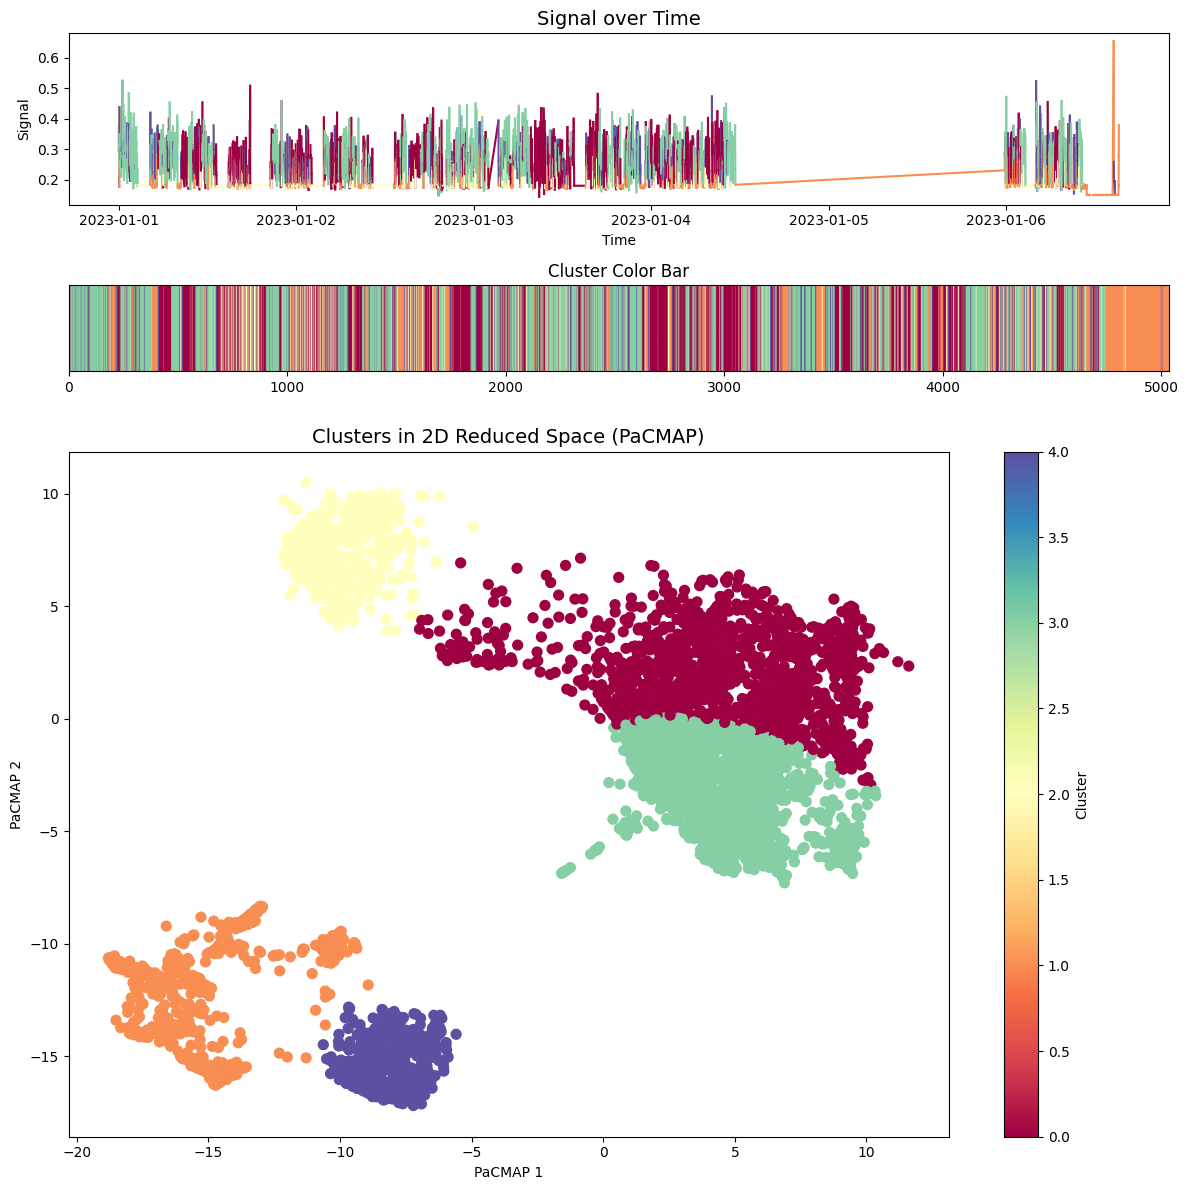

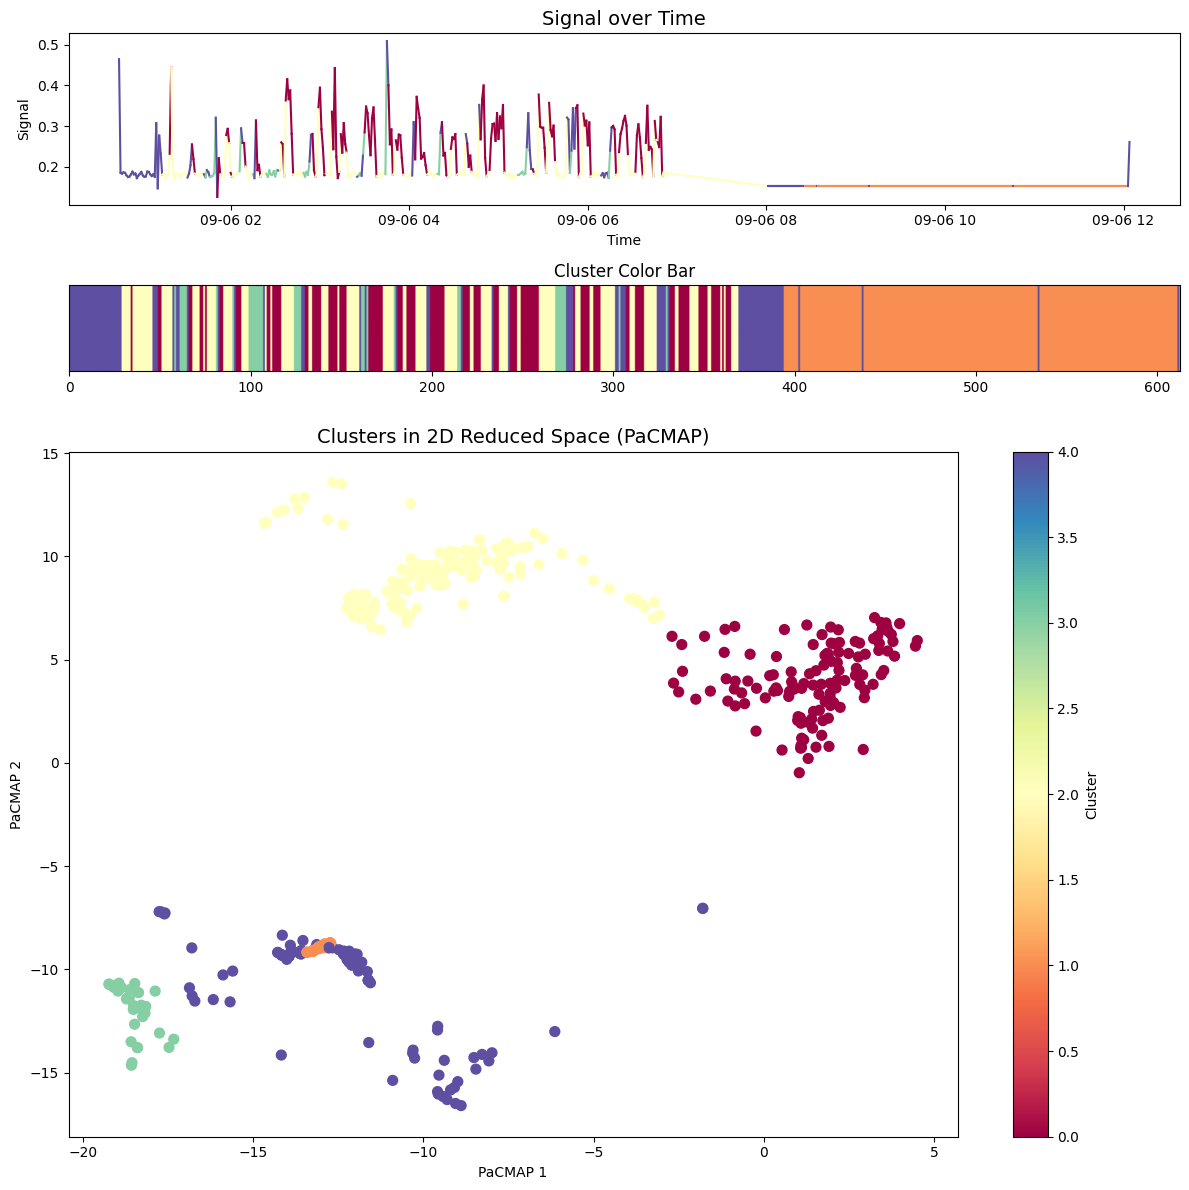

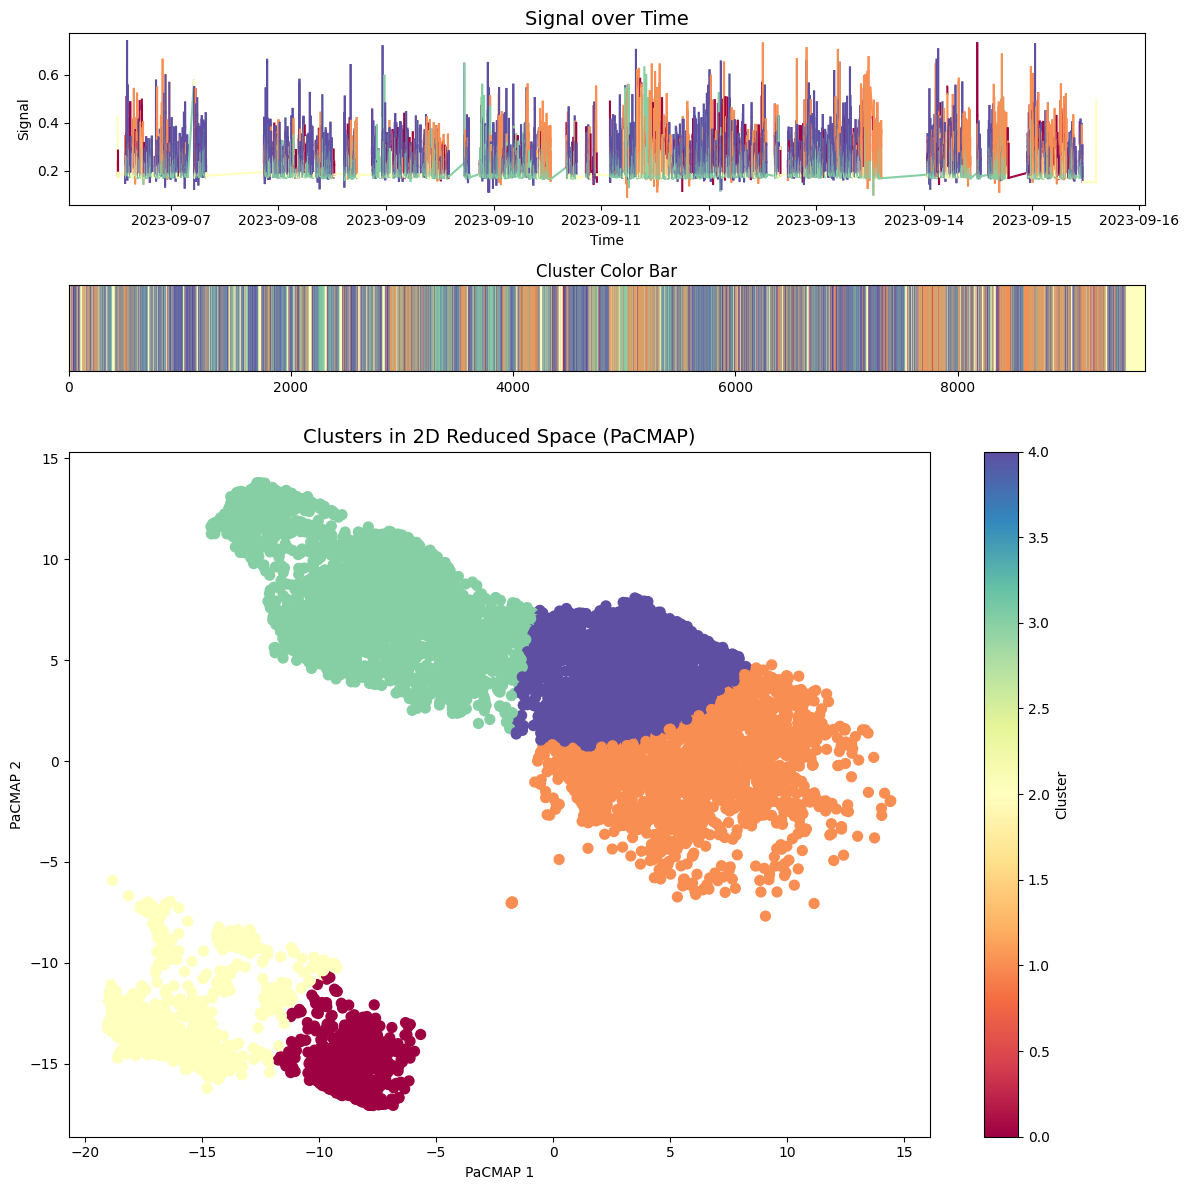

The MOF Falta de aceite hidráulico


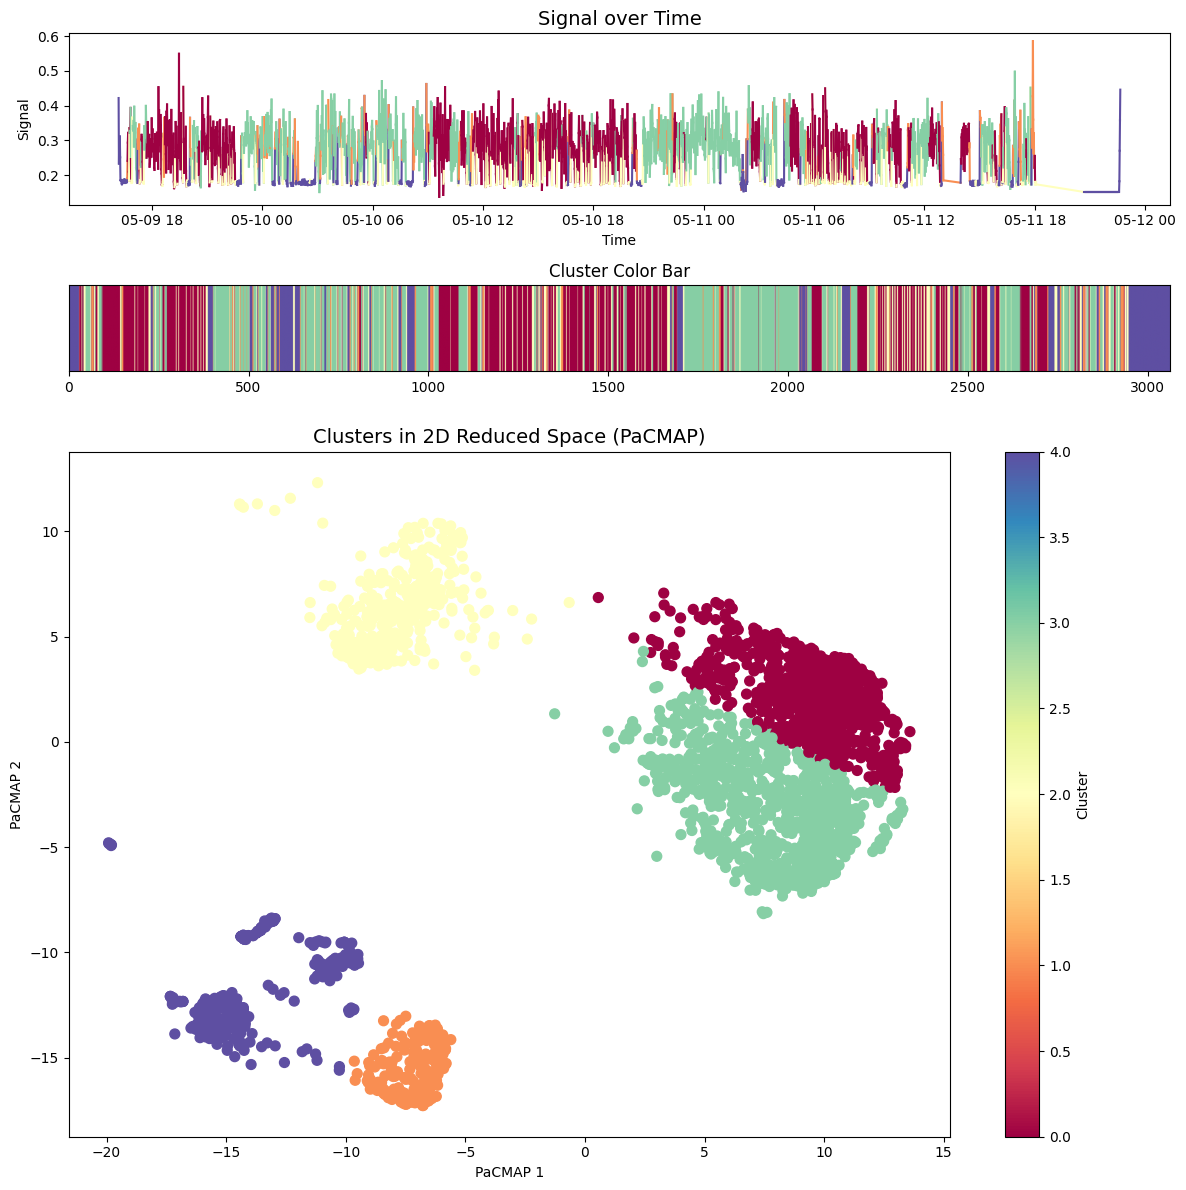

The MOF Lubricación  deficiente


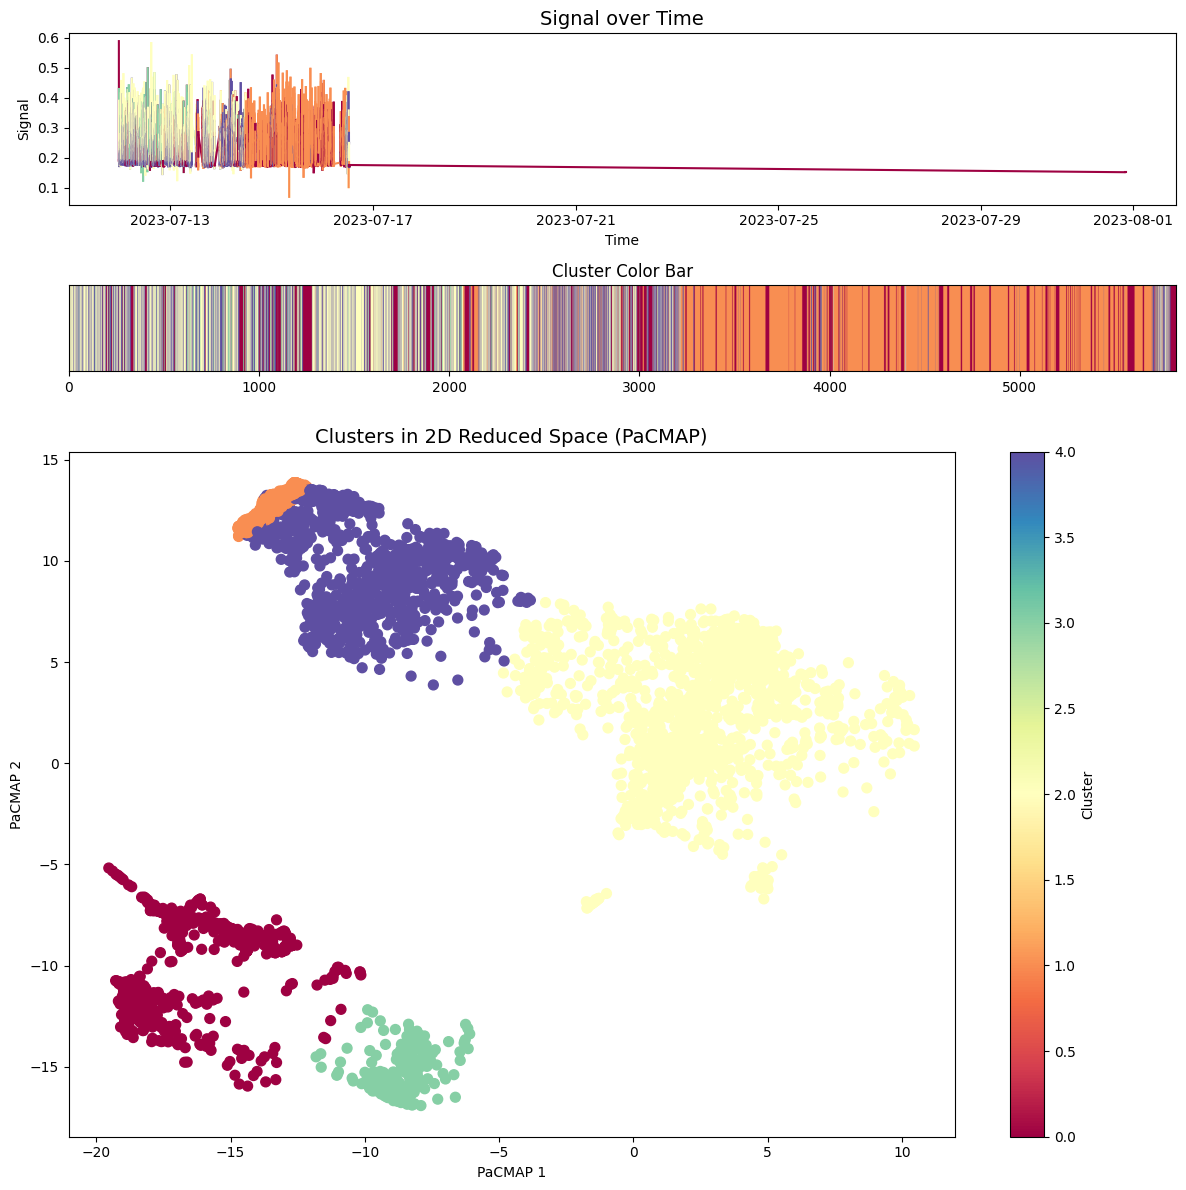

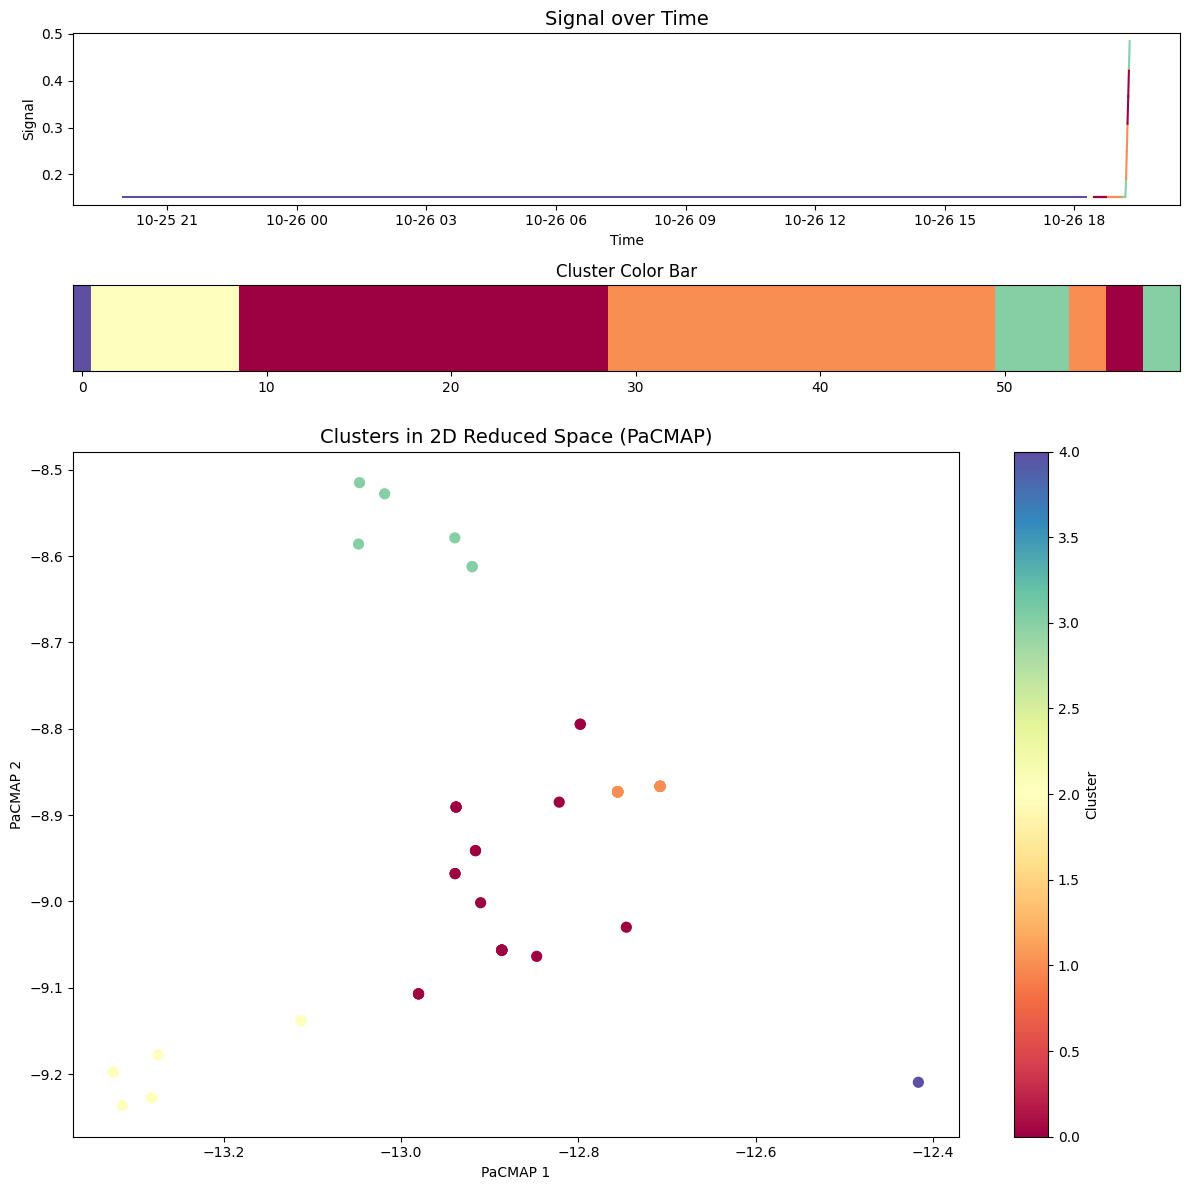

The MOF Temperatura fuera de rango


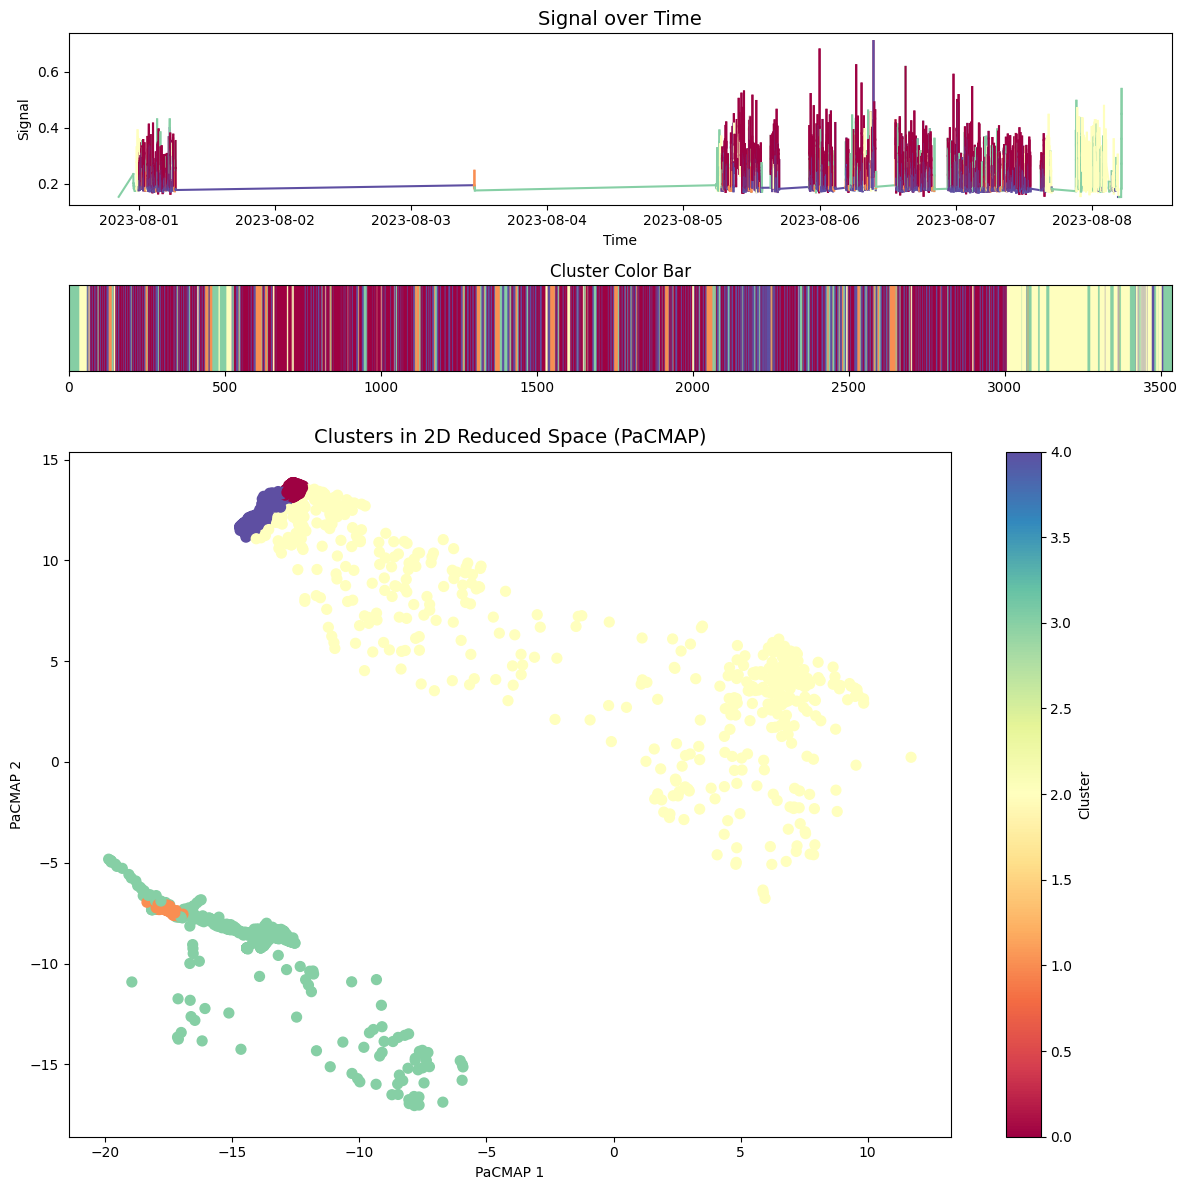

The MOF Bomba hidráulica con fuga


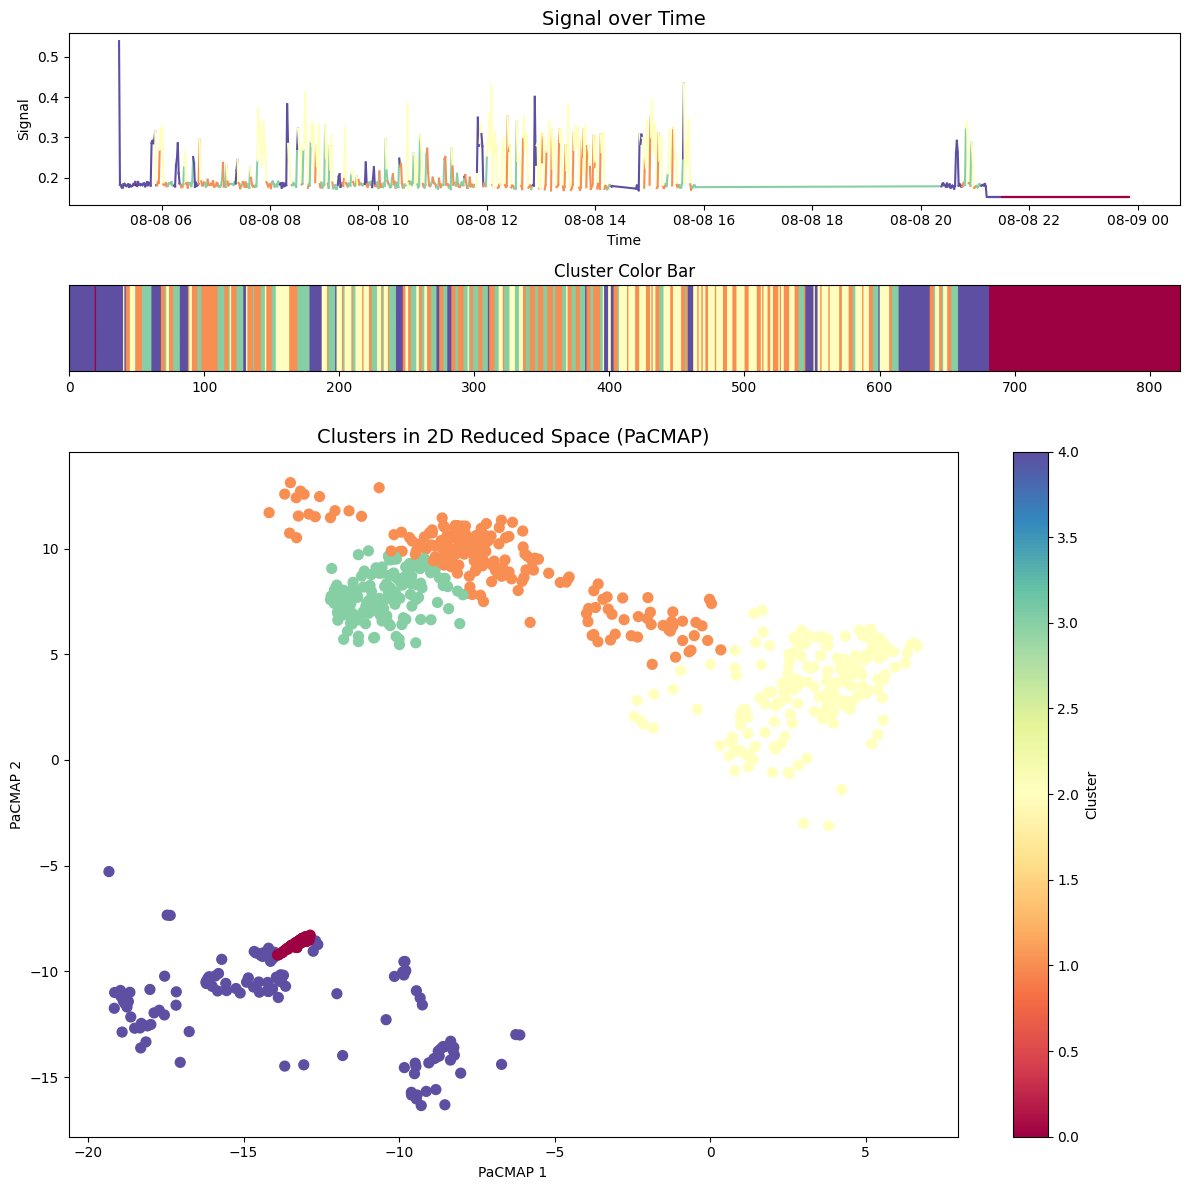

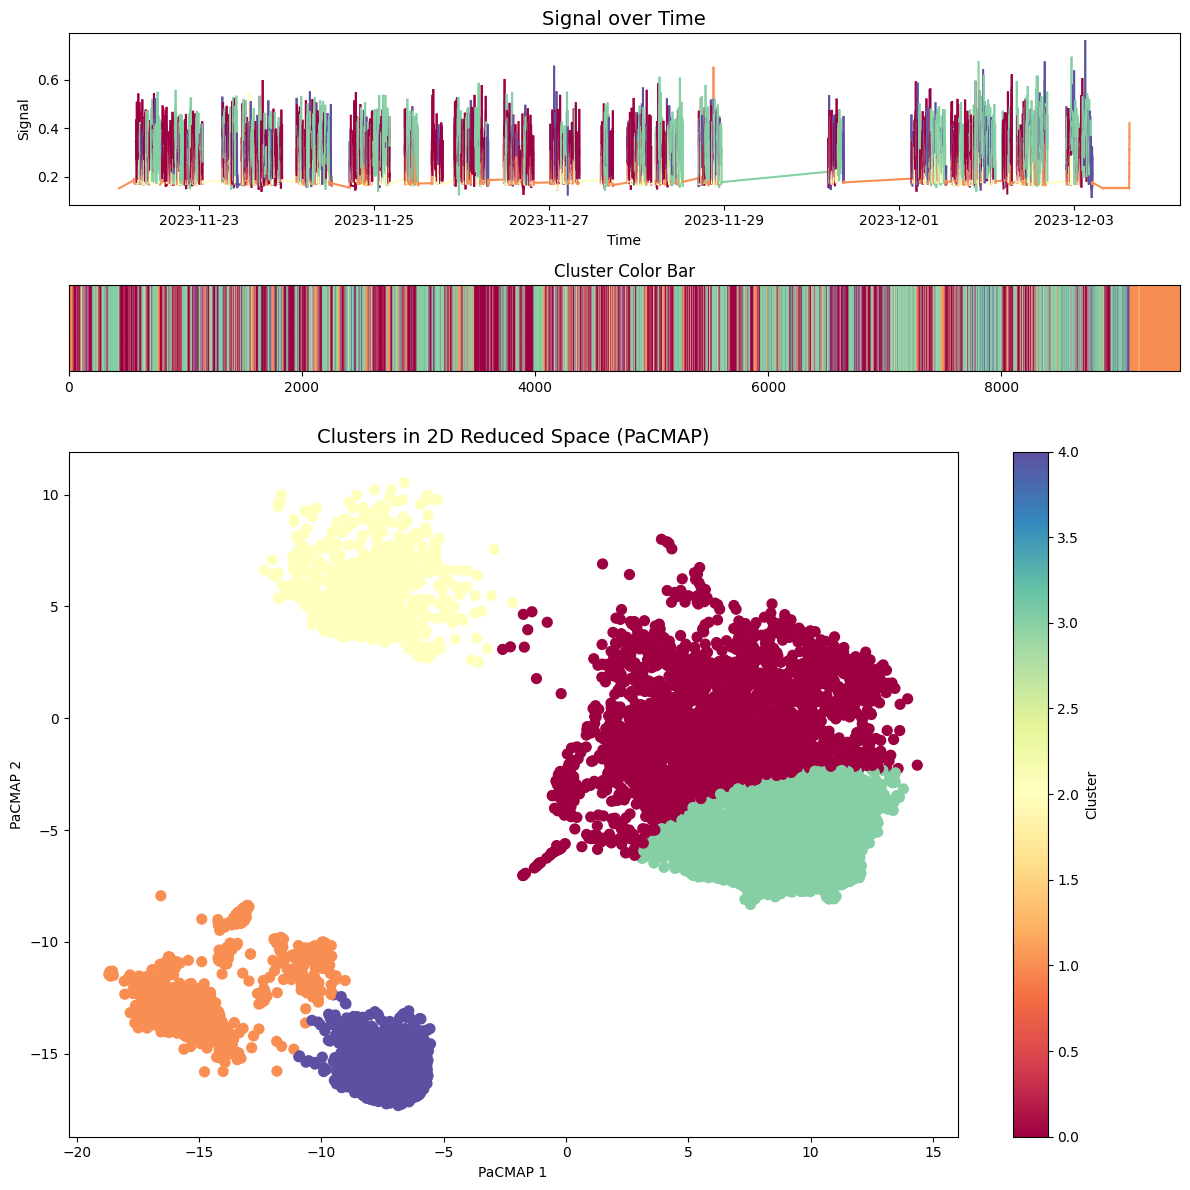

The MOF Fuga de aceite


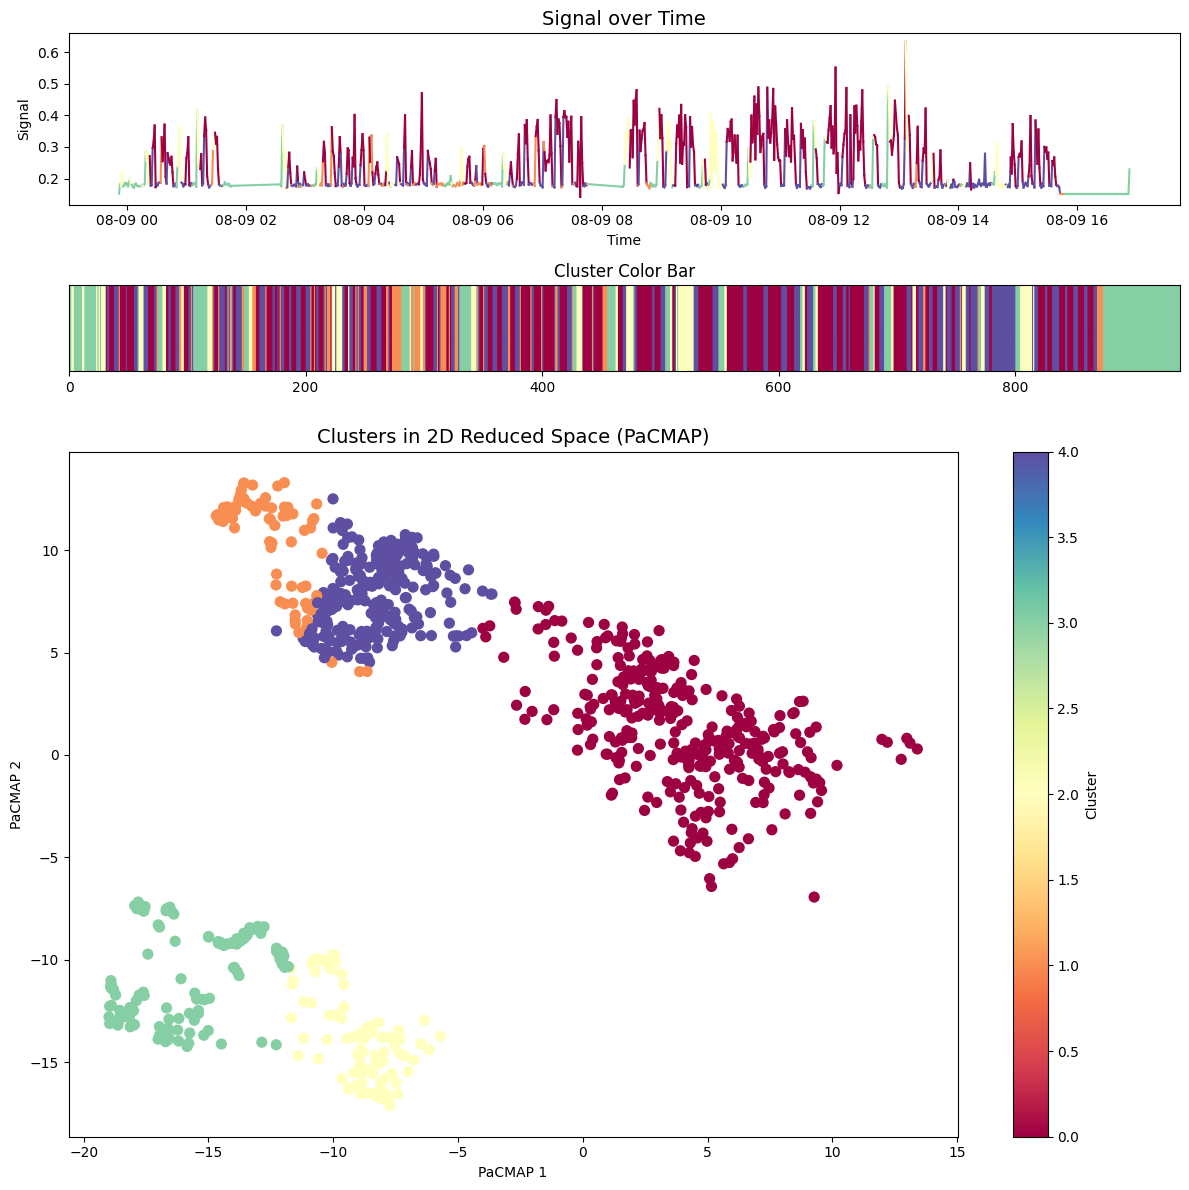

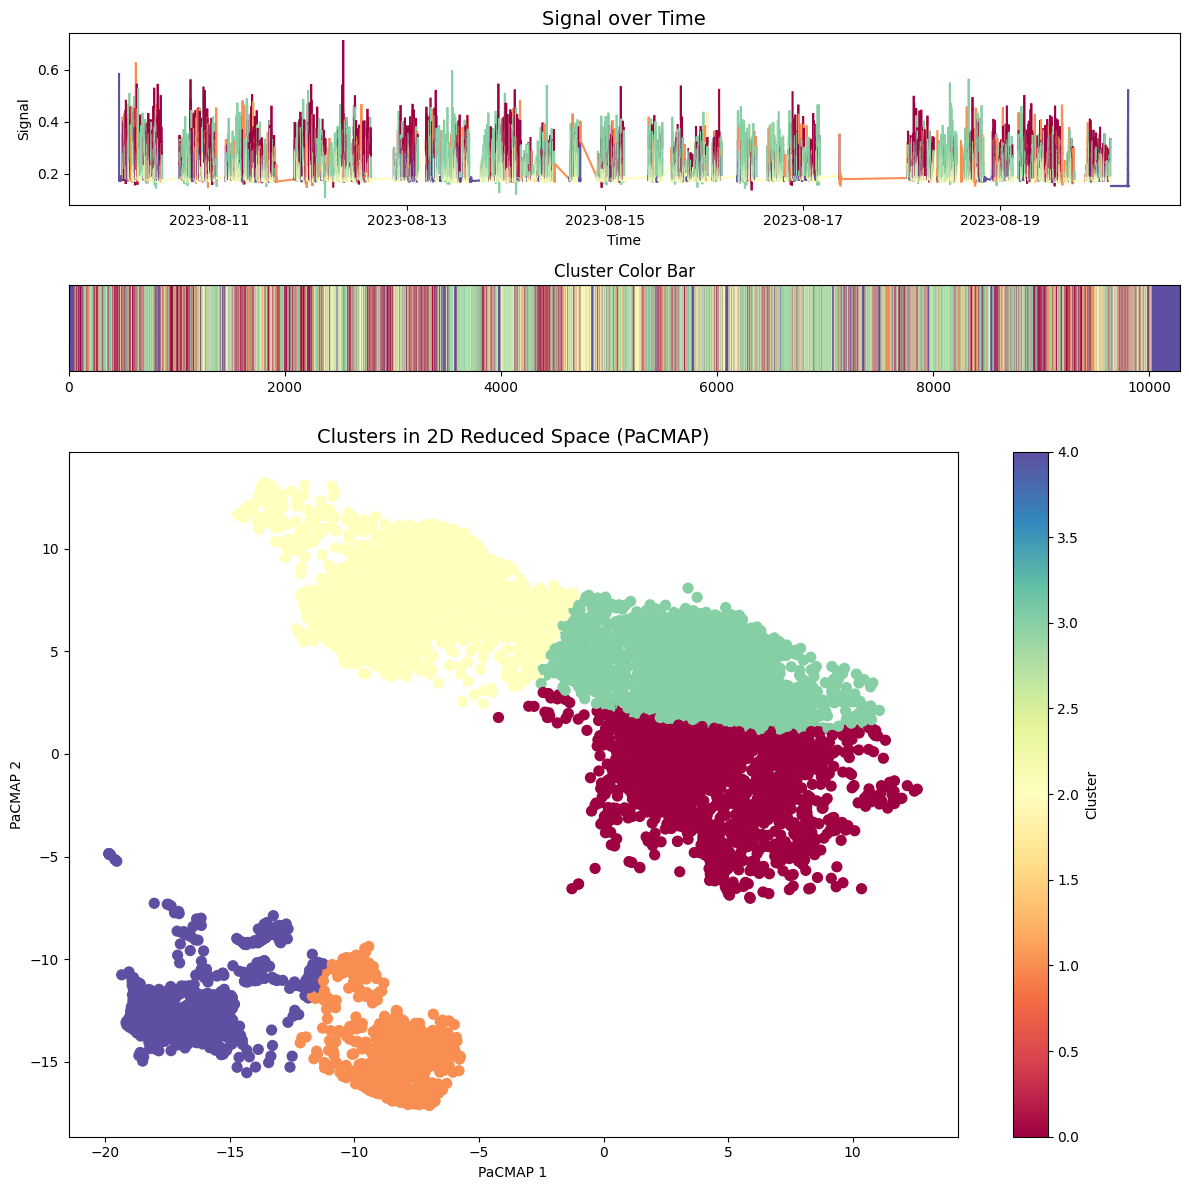

The MOF Falla sistema de hidroset-poste


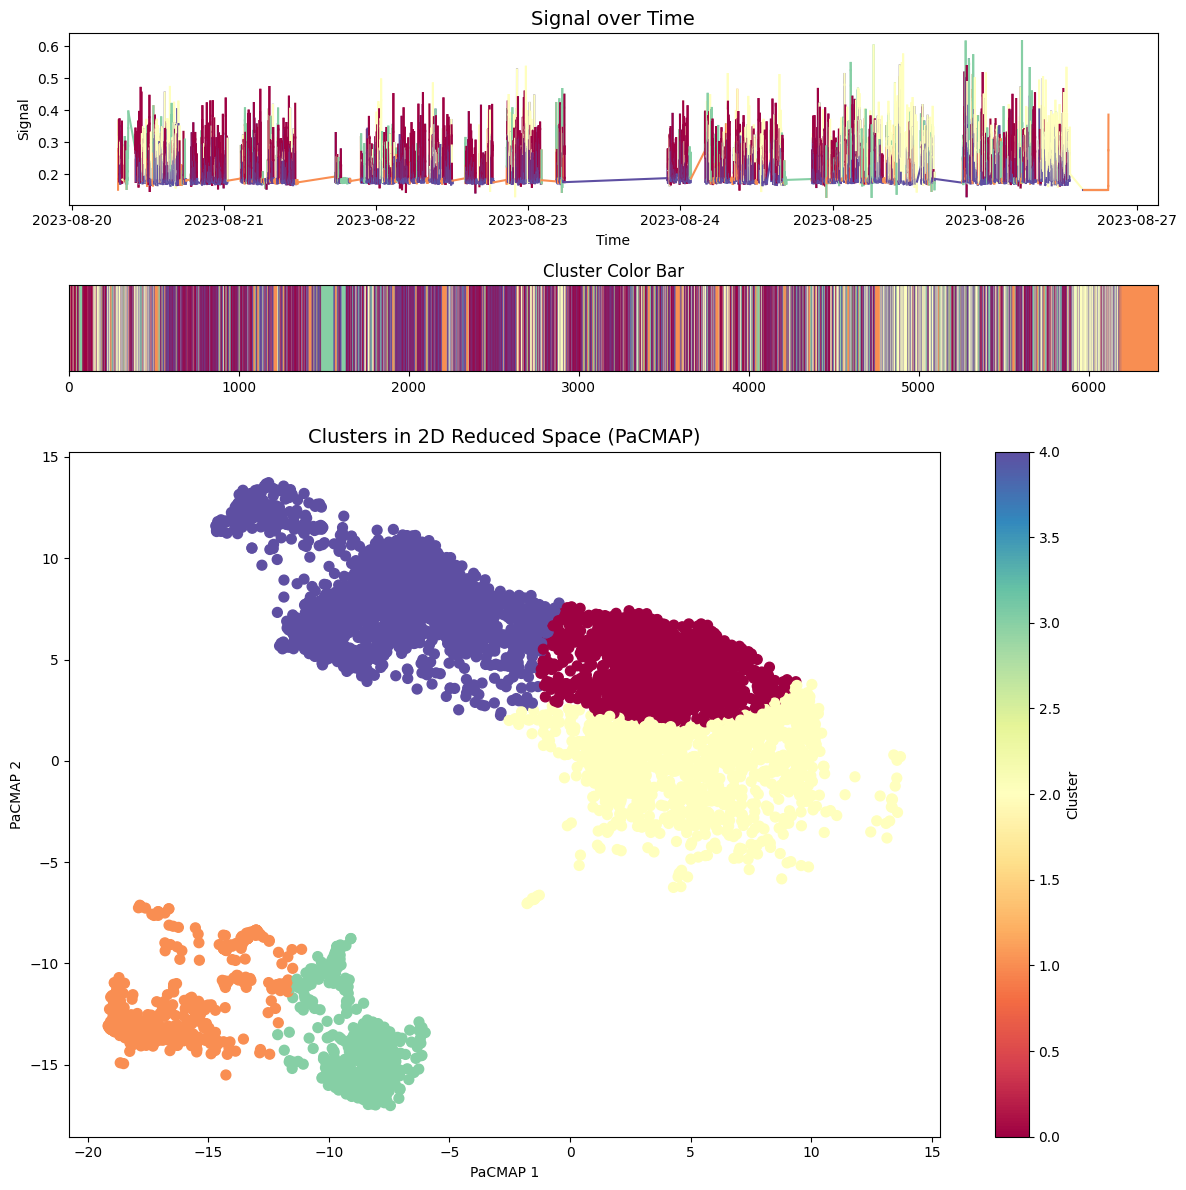

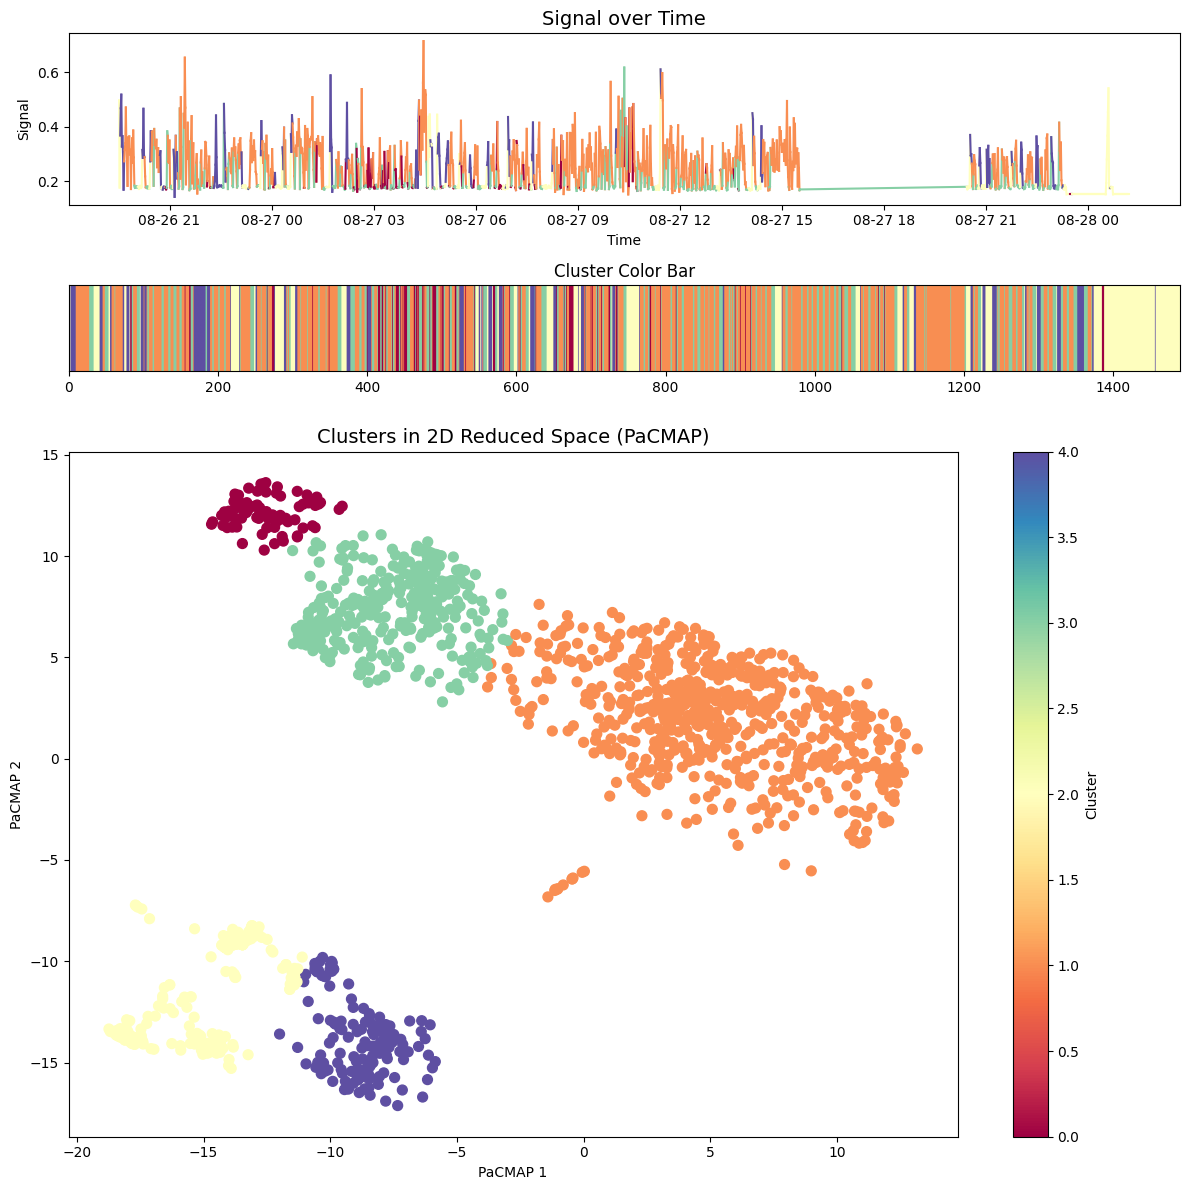

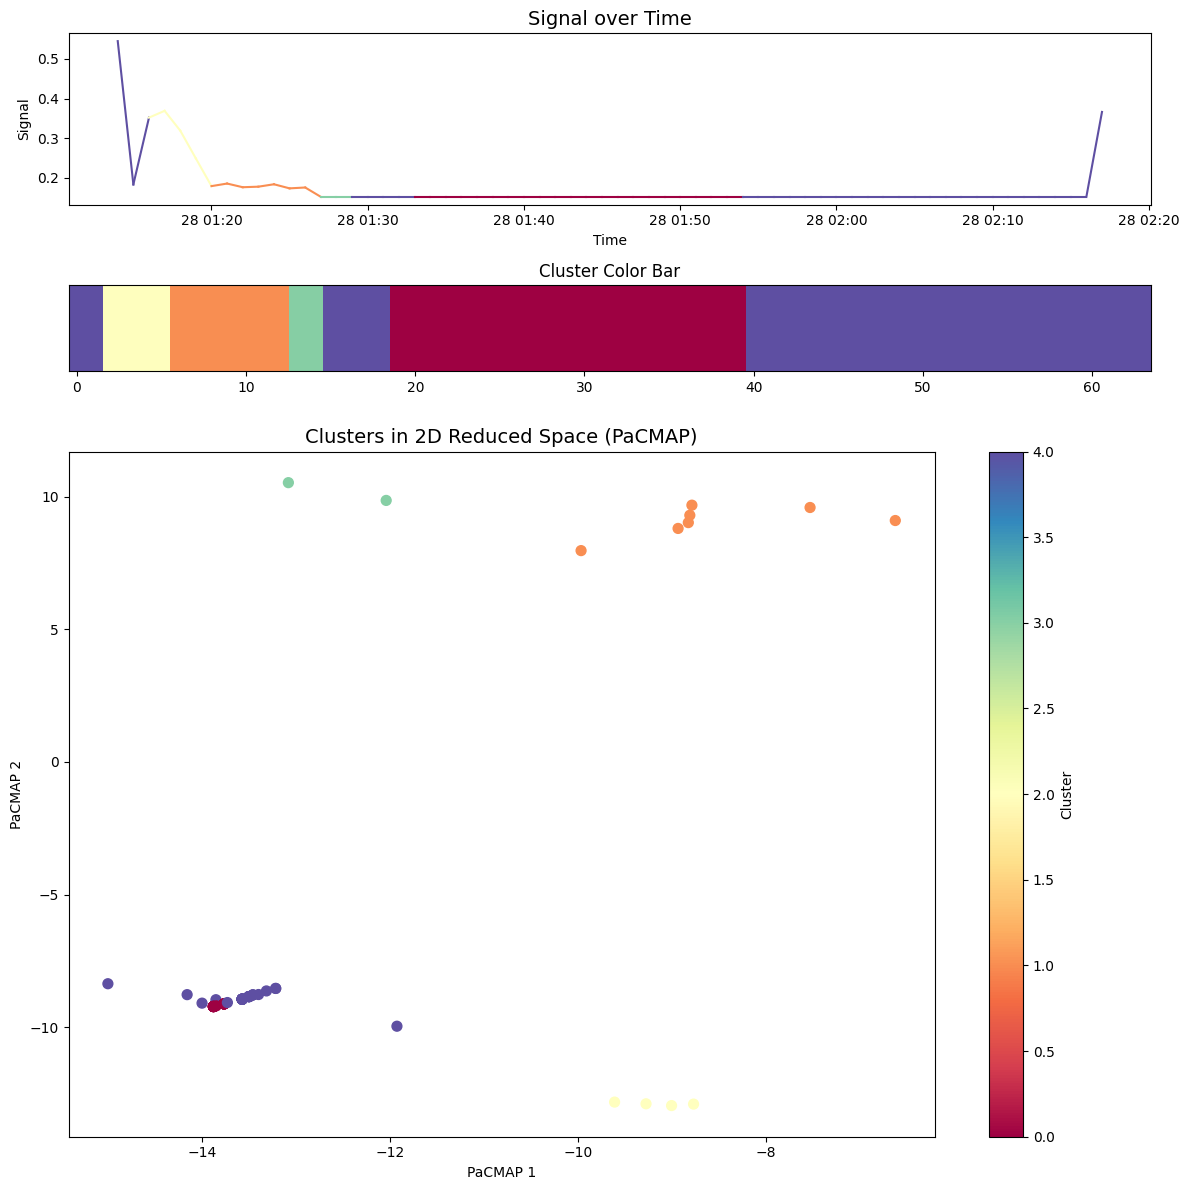

The MOF Mandibulas o revestimiento suelto


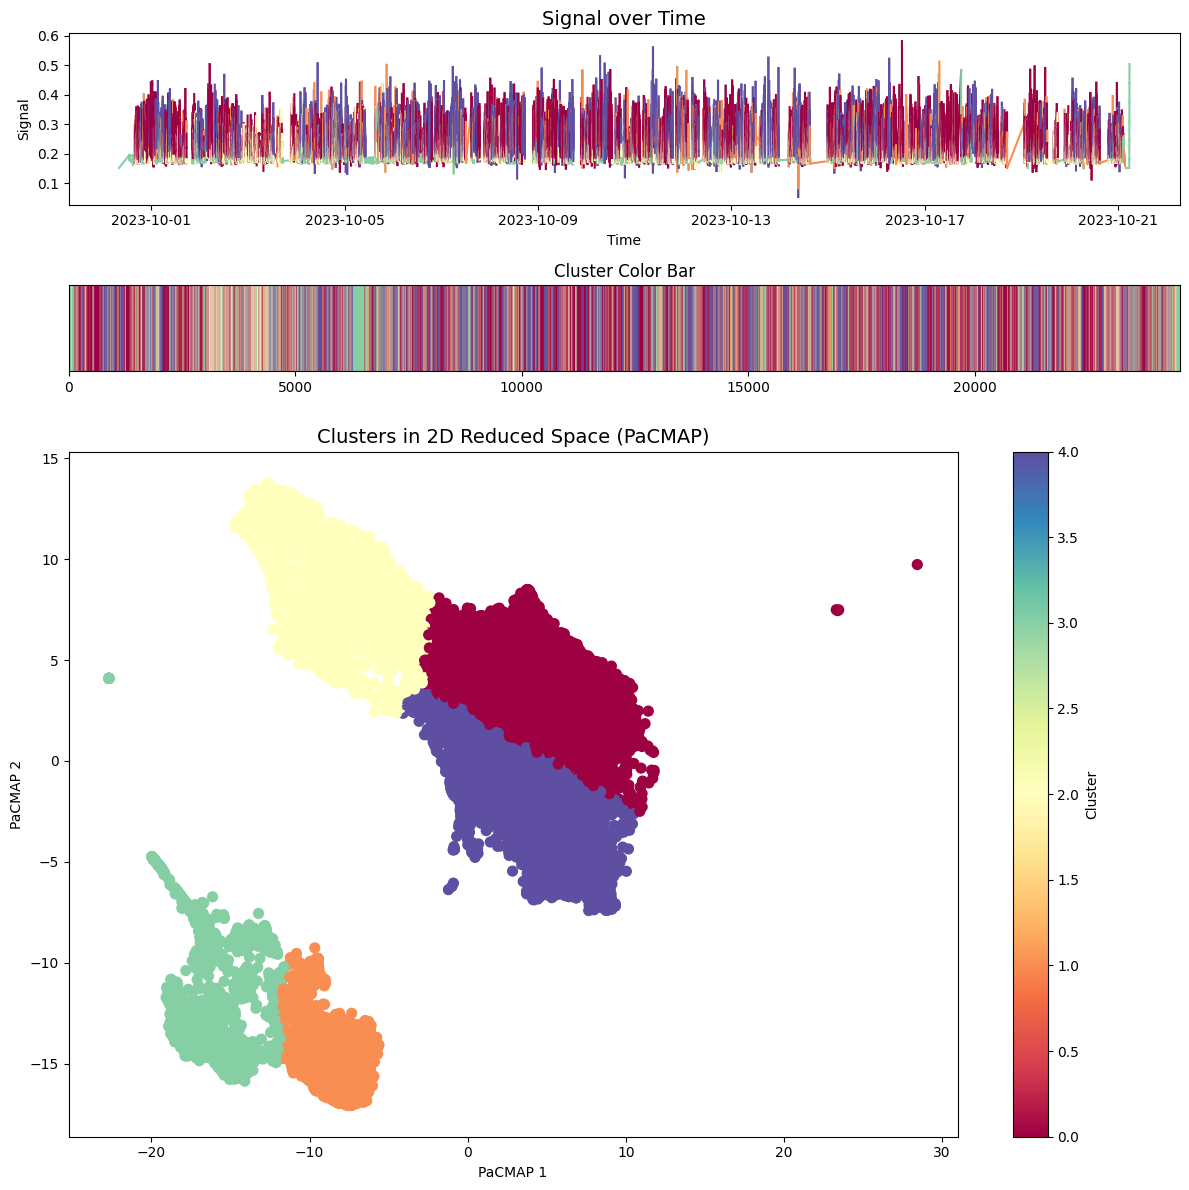

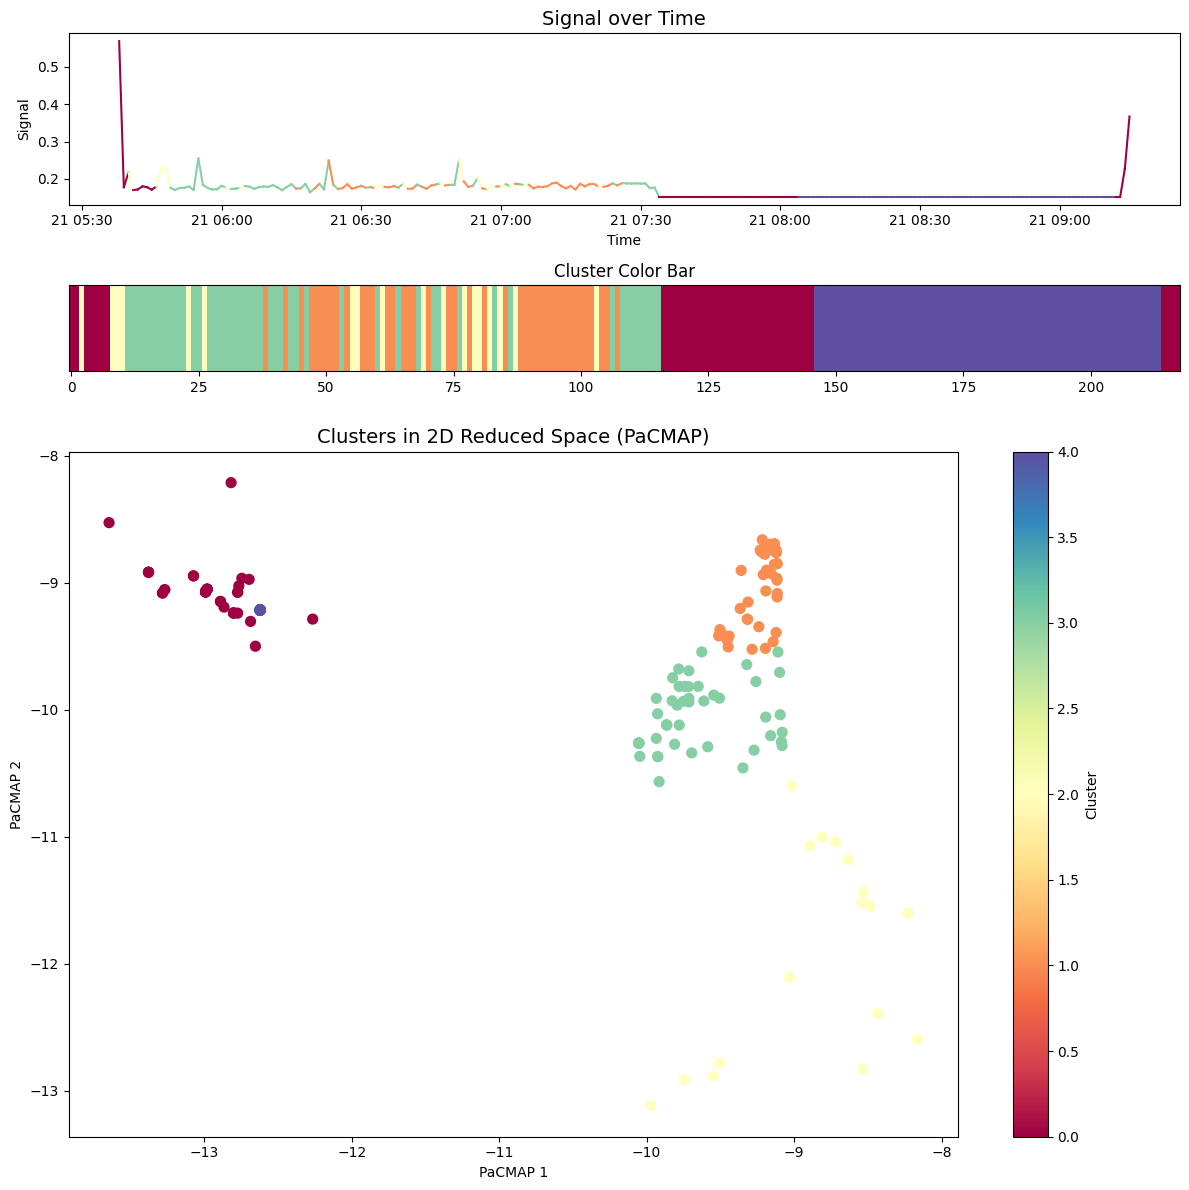

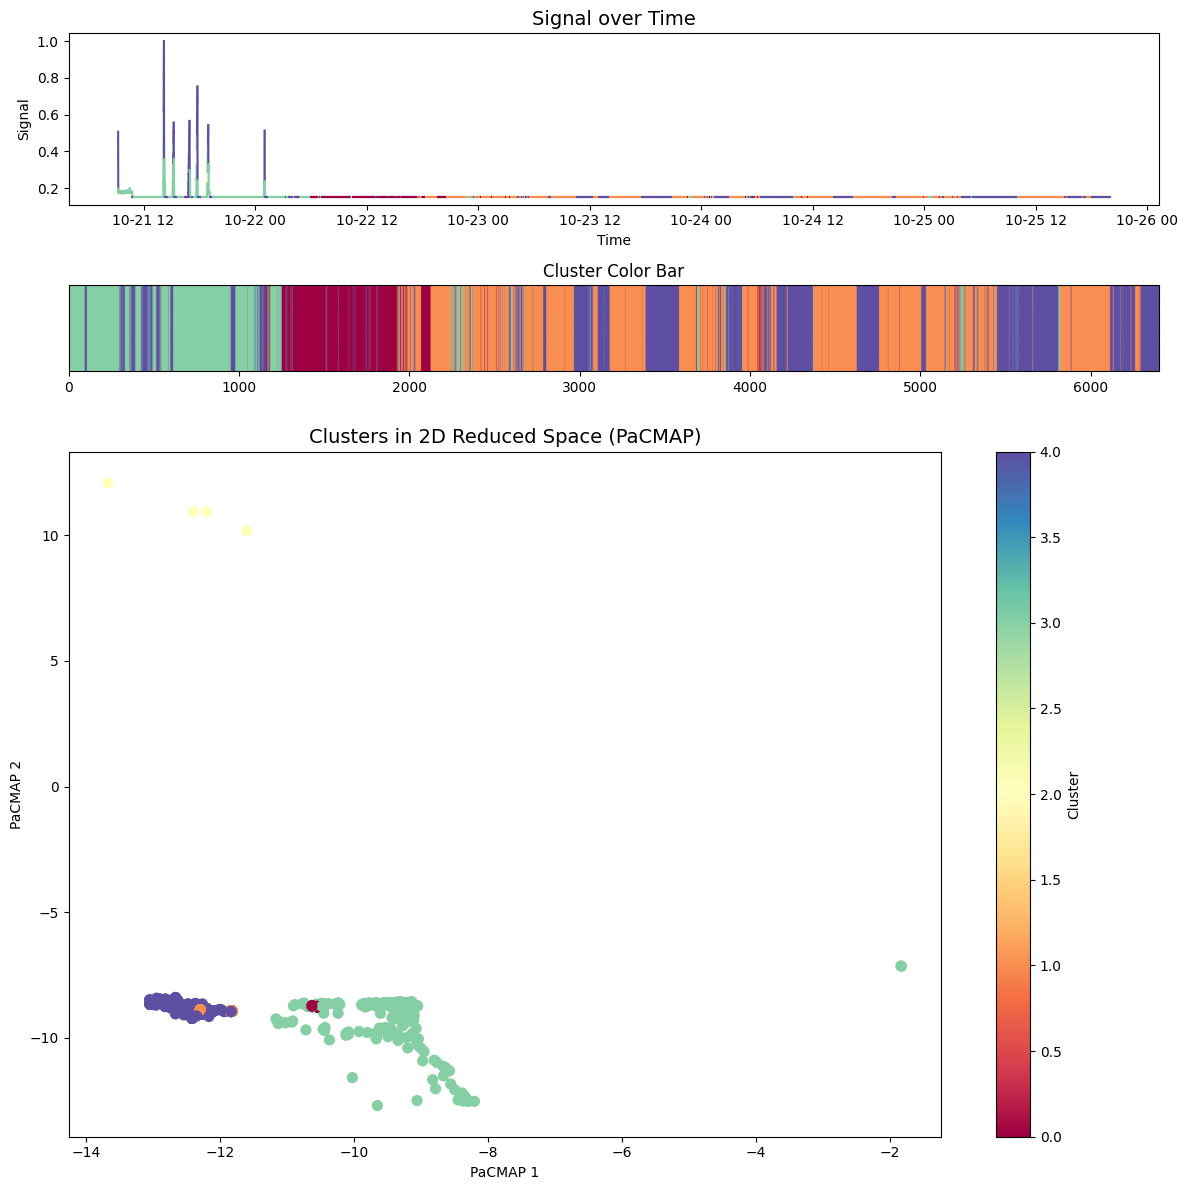

In [18]:
pacmapModel                 = pacmap.PaCMAP(    n_components = 2, 
                                                random_state = 40, 
                                                save_tree    = True)

clusterAlg                  = GaussianMixture(  n_components = 5, 
                                                random_state = 3, 
                                                n_init       = 5)
pacmapModel.fit(normalizedHealthy[preData.efficiencyCr1 + preData.addEfficiencyCr1])            # Train with the healthy data

for mof, idxTrajectList in trajectory.items():
    print(f"The MOF {mof}")
    for idx,curTraject in enumerate(idxTrajectList):

        # -----------------------------
        # Transform the PACMAP
        # -----------------------------
        efficiencyTraject   = curTraject[preData.efficiencyCr1 + preData.addEfficiencyCr1]     # Extract the 
        # print("--------------------")
        # print(efficiencyTraject.shape)
        embedding           = pacmapModel.transform(efficiencyTraject)
        dim1 = embedding[:, 0]  # First dimension from pacmap (size 100)
        dim2 = embedding[:, 1]  # Second dimension from pacmap (size 100)
        # print(embedding.shape)

        # -----------------------------
        # Cluster
        # -----------------------------
        clusters            = clusterAlg.fit_predict(embedding)
        # print(clusterRst.shape)
        
        # -----------------------------
        # Plot
        # -----------------------------
        testSignal = curTraject["Potencia(kW)"]
        time       = curTraject["tiempo"]

        norm = Normalize(vmin=clusters.min(), vmax=clusters.max())
        colors = plt.cm.Spectral(norm(clusters))  # Use the 'Spectral' colormap

        # Create subplots
        fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 12), gridspec_kw={'height_ratios': [1, 0.5, 4]})

        # Plot 1: Signal over time with color from cluster
        for i in range(len(testSignal) - 1):
            ax1.plot(time[i:i+2], testSignal[i:i+2], color=colors[i])  # Plot segments of the signal with cluster color

        ax1.set_title('Signal over Time', fontsize=14)
        ax1.set_xlabel('Time')
        ax1.set_ylabel('Signal')

        # Plot 2: Colorbar for clusters
        ax2.imshow([colors], aspect='auto')  # Display the color range horizontally
        ax2.set_yticks([])  # Remove y-axis ticks
        ax2.set_title('Cluster Color Bar')

        # Plot 3: Clusters in 2D Reduced Space (PaCMAP embedding)
        scatter = ax3.scatter(embedding[:, 0], embedding[:, 1], c=clusters, cmap='Spectral', s=50)
        ax3.set_title('Clusters in 2D Reduced Space (PaCMAP)', fontsize=14)
        ax3.set_xlabel('PaCMAP 1')
        ax3.set_ylabel('PaCMAP 2')

        # Add a colorbar for the clusters in the 2D space
        fig.colorbar(scatter, ax=ax3, label='Cluster')

        plt.tight_layout()
        plt.show()

The MOF Válvula defectuosa


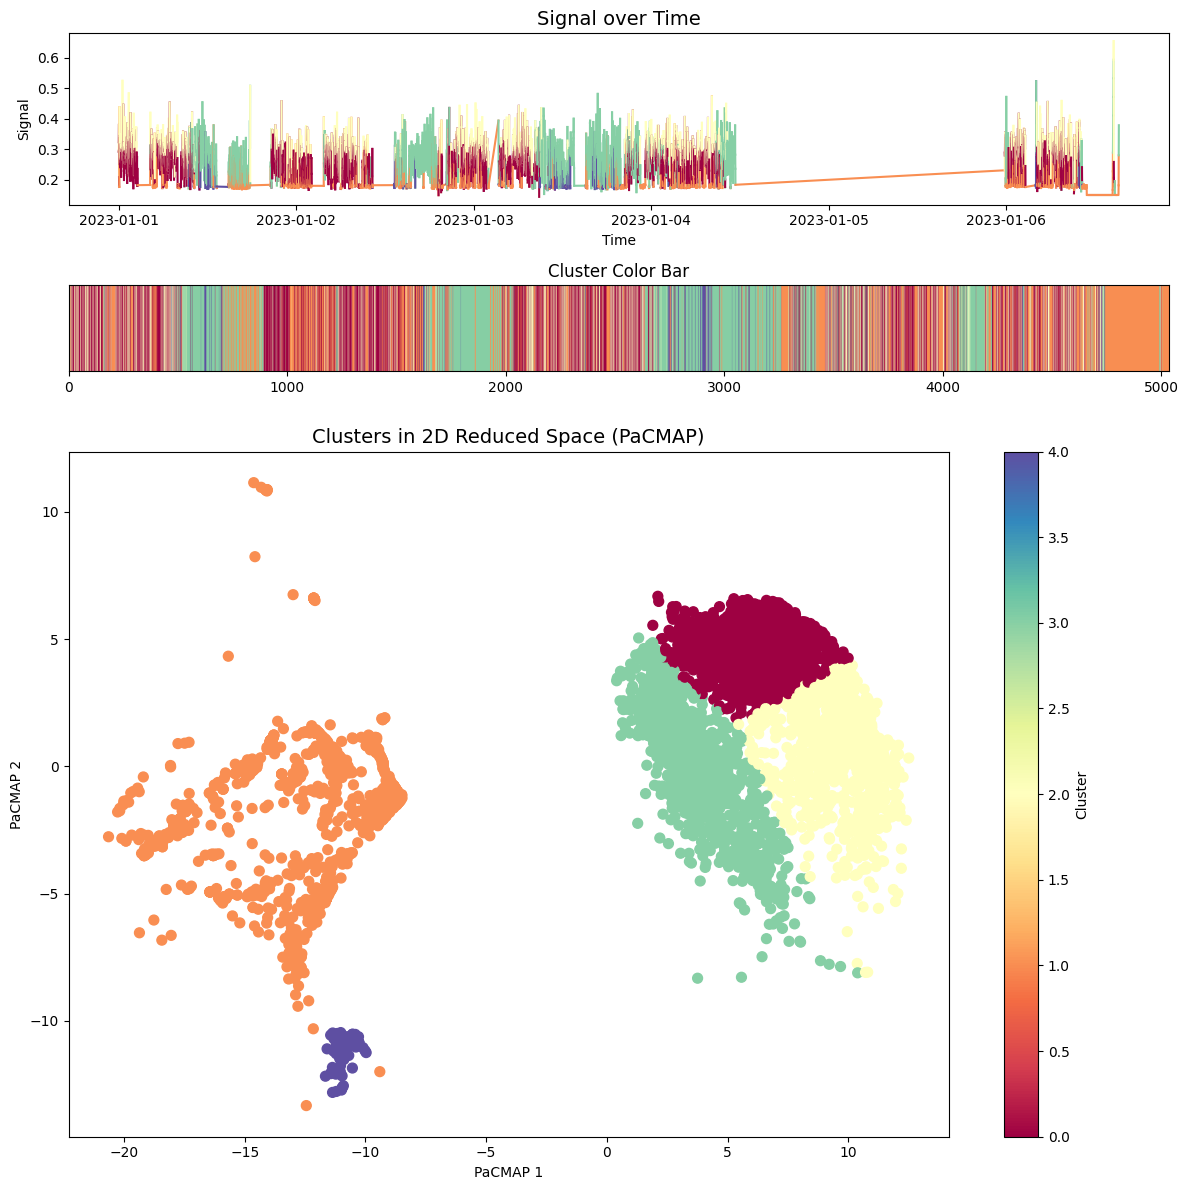

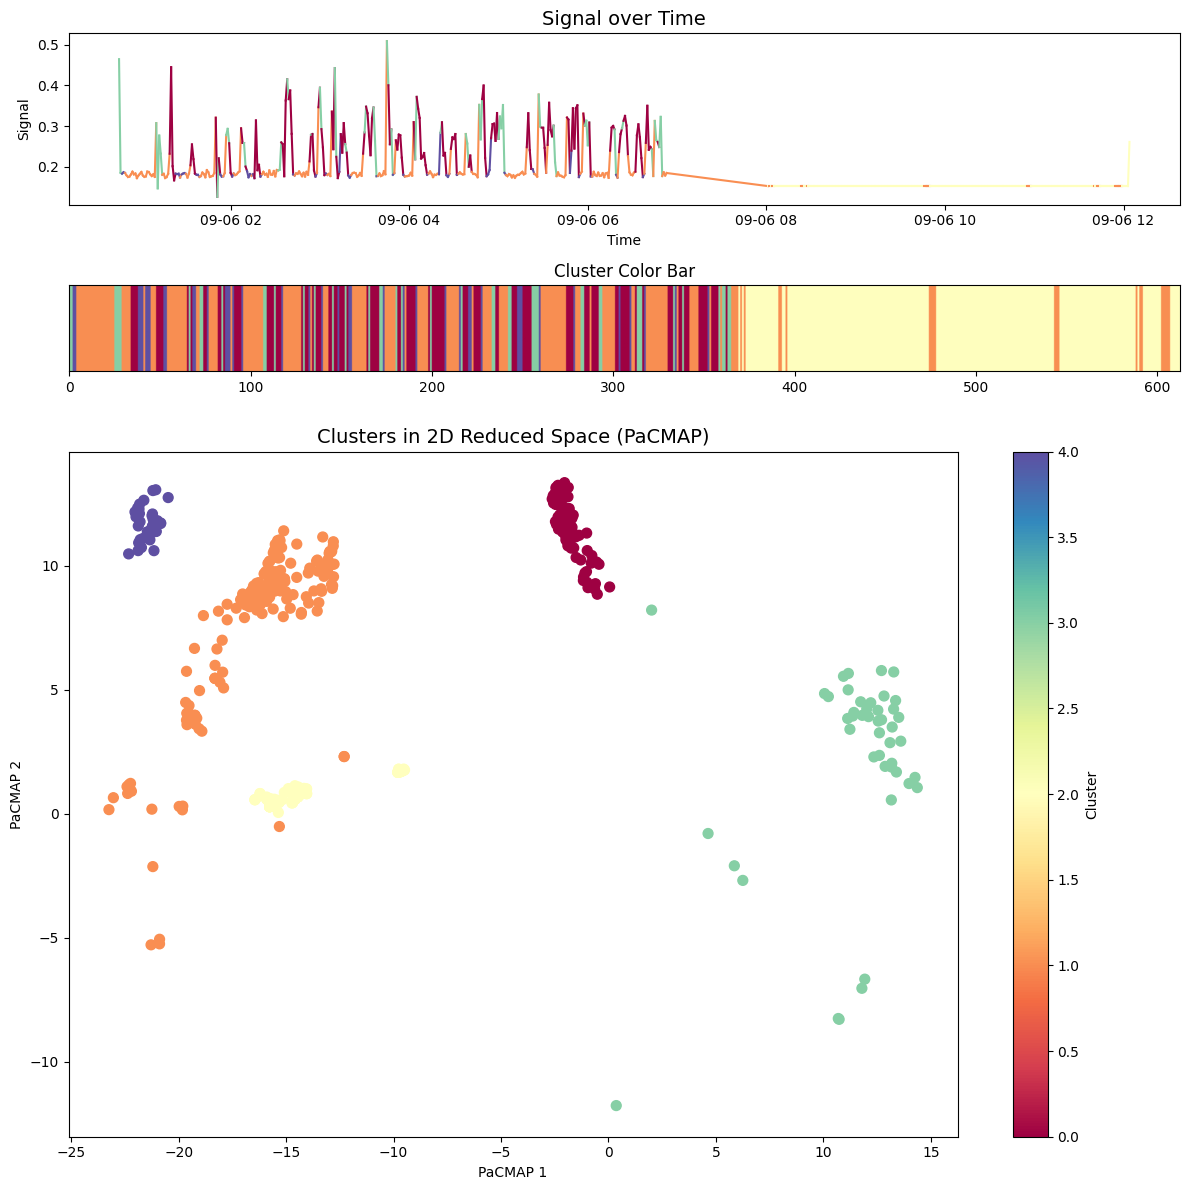

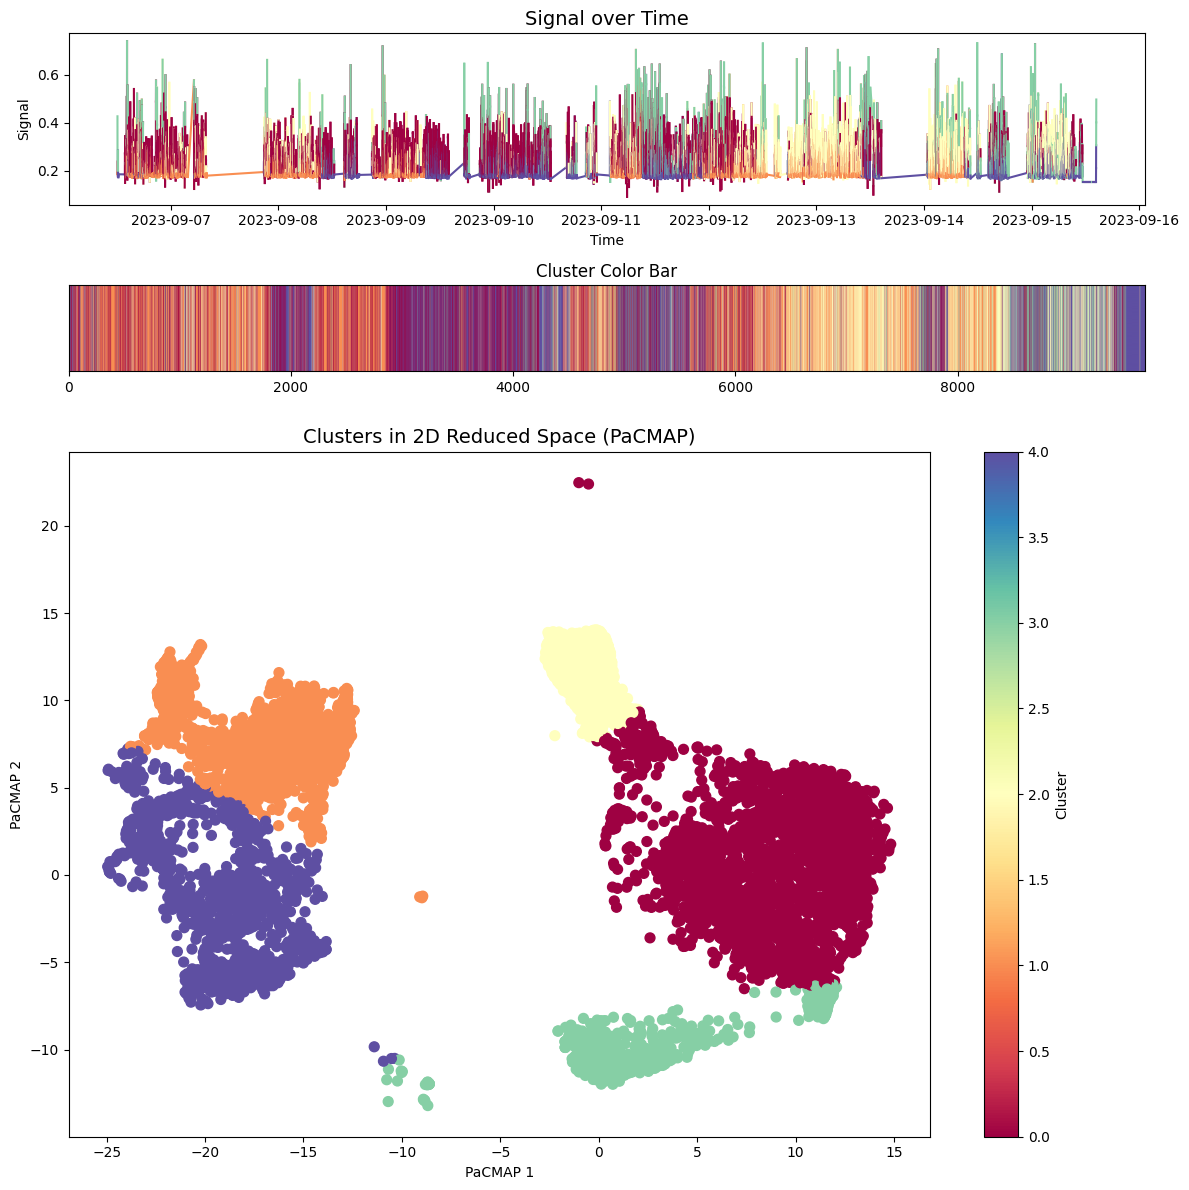

The MOF Falta de aceite hidráulico


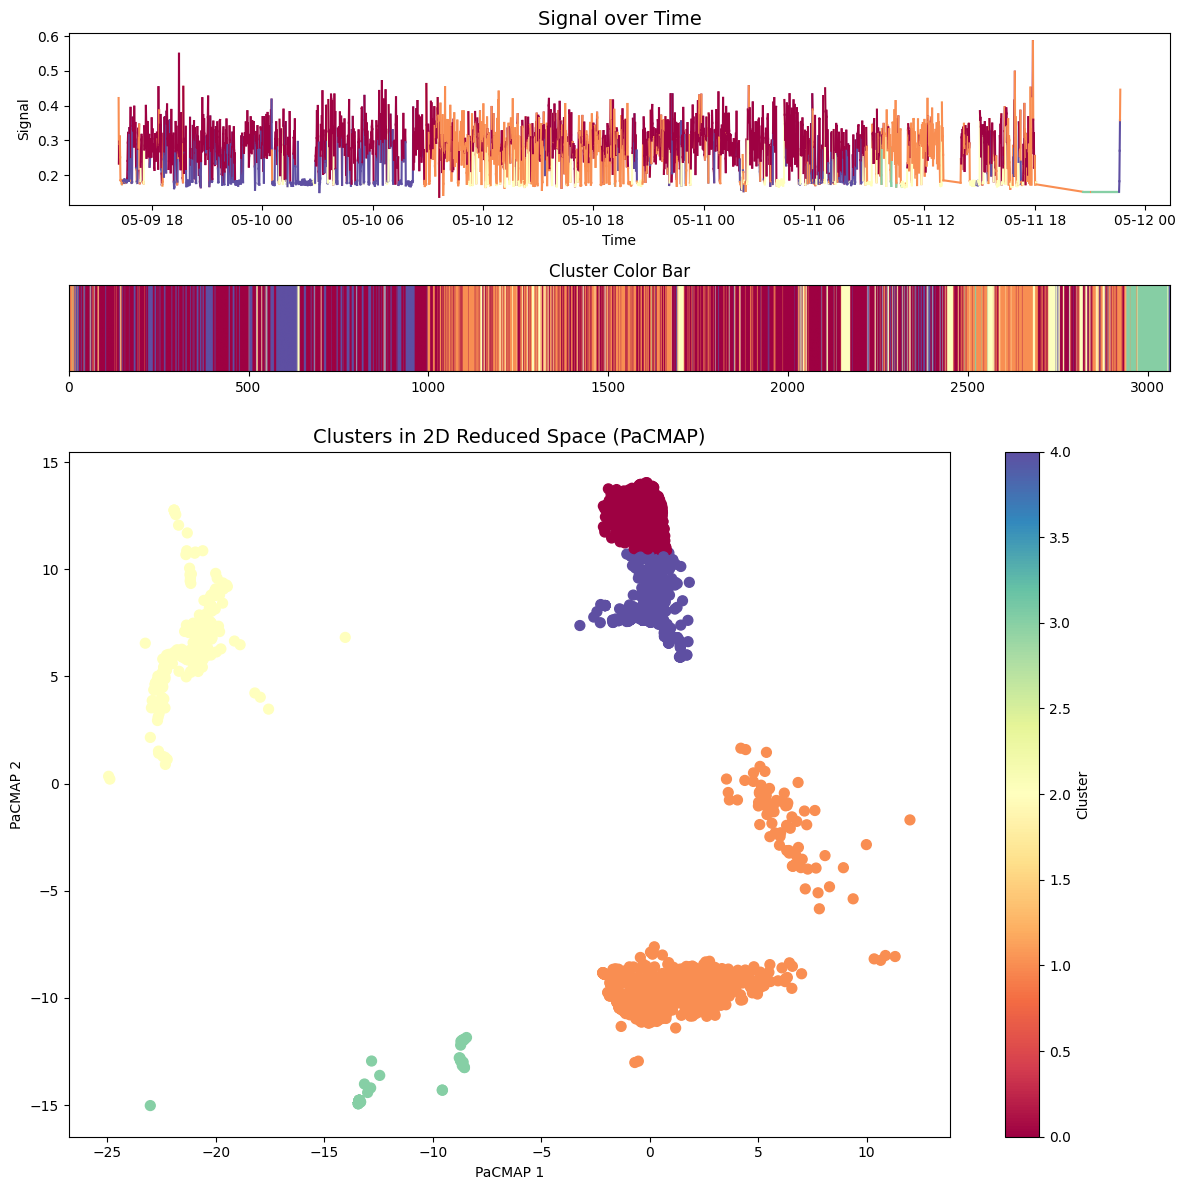

The MOF Lubricación  deficiente


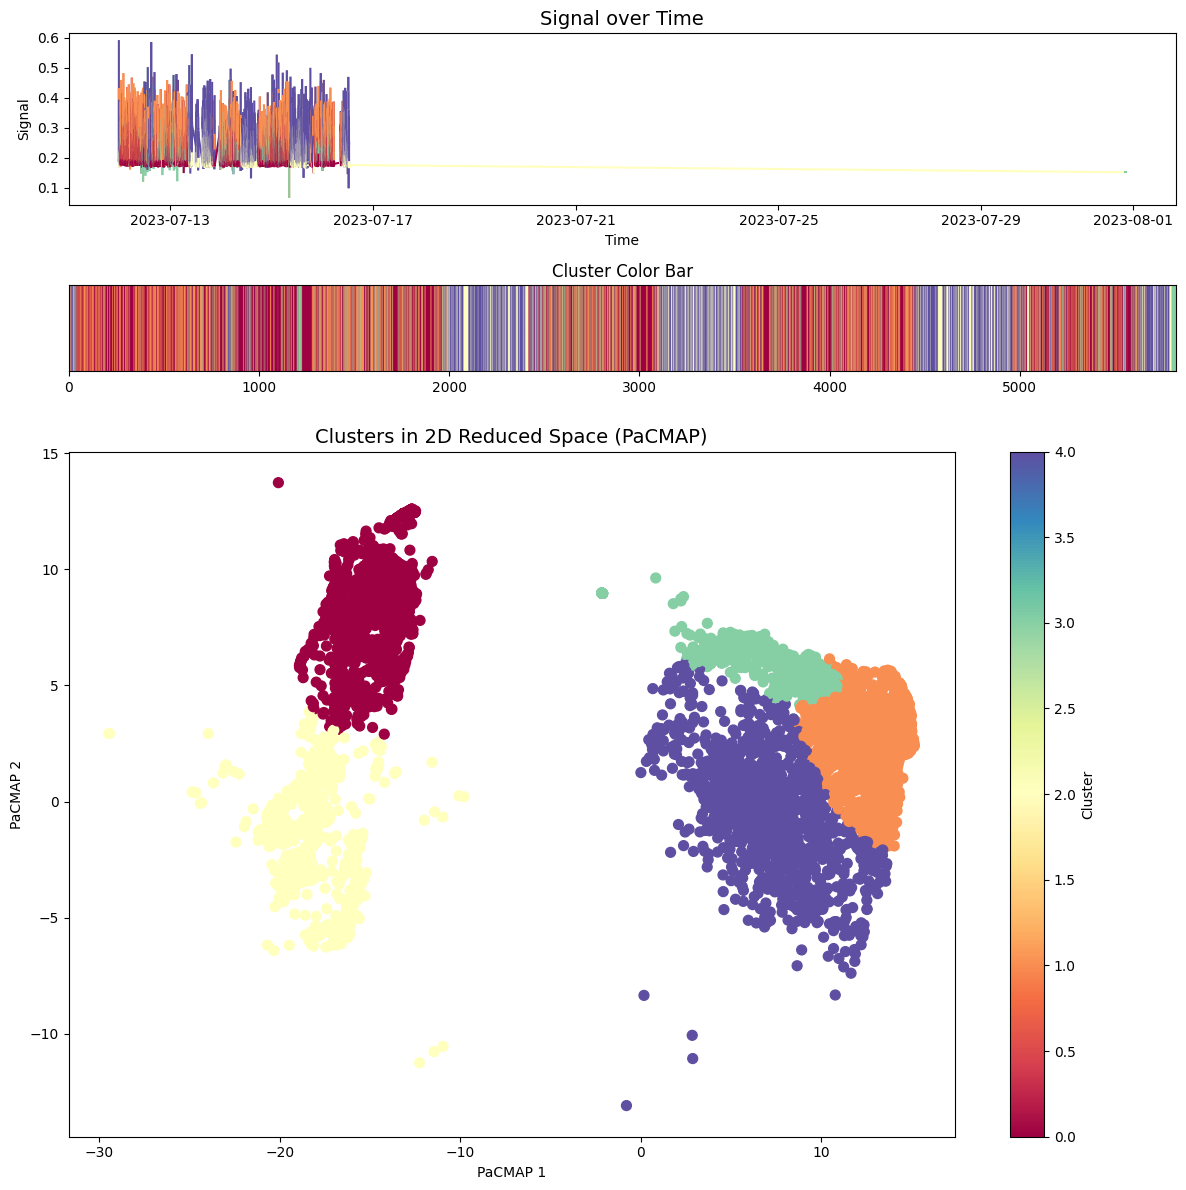

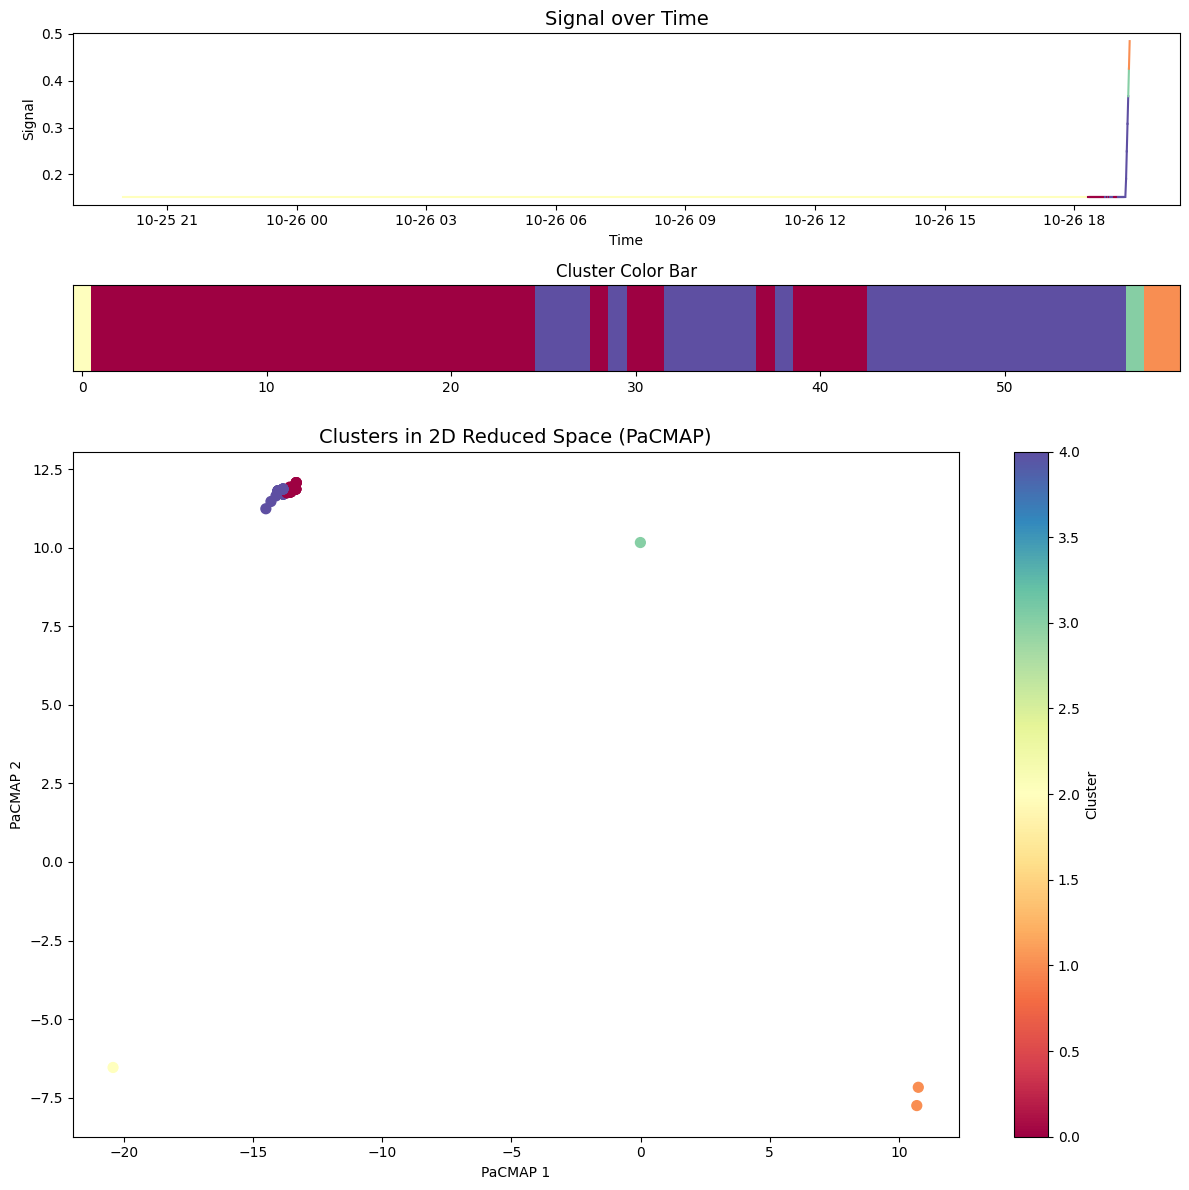

The MOF Temperatura fuera de rango


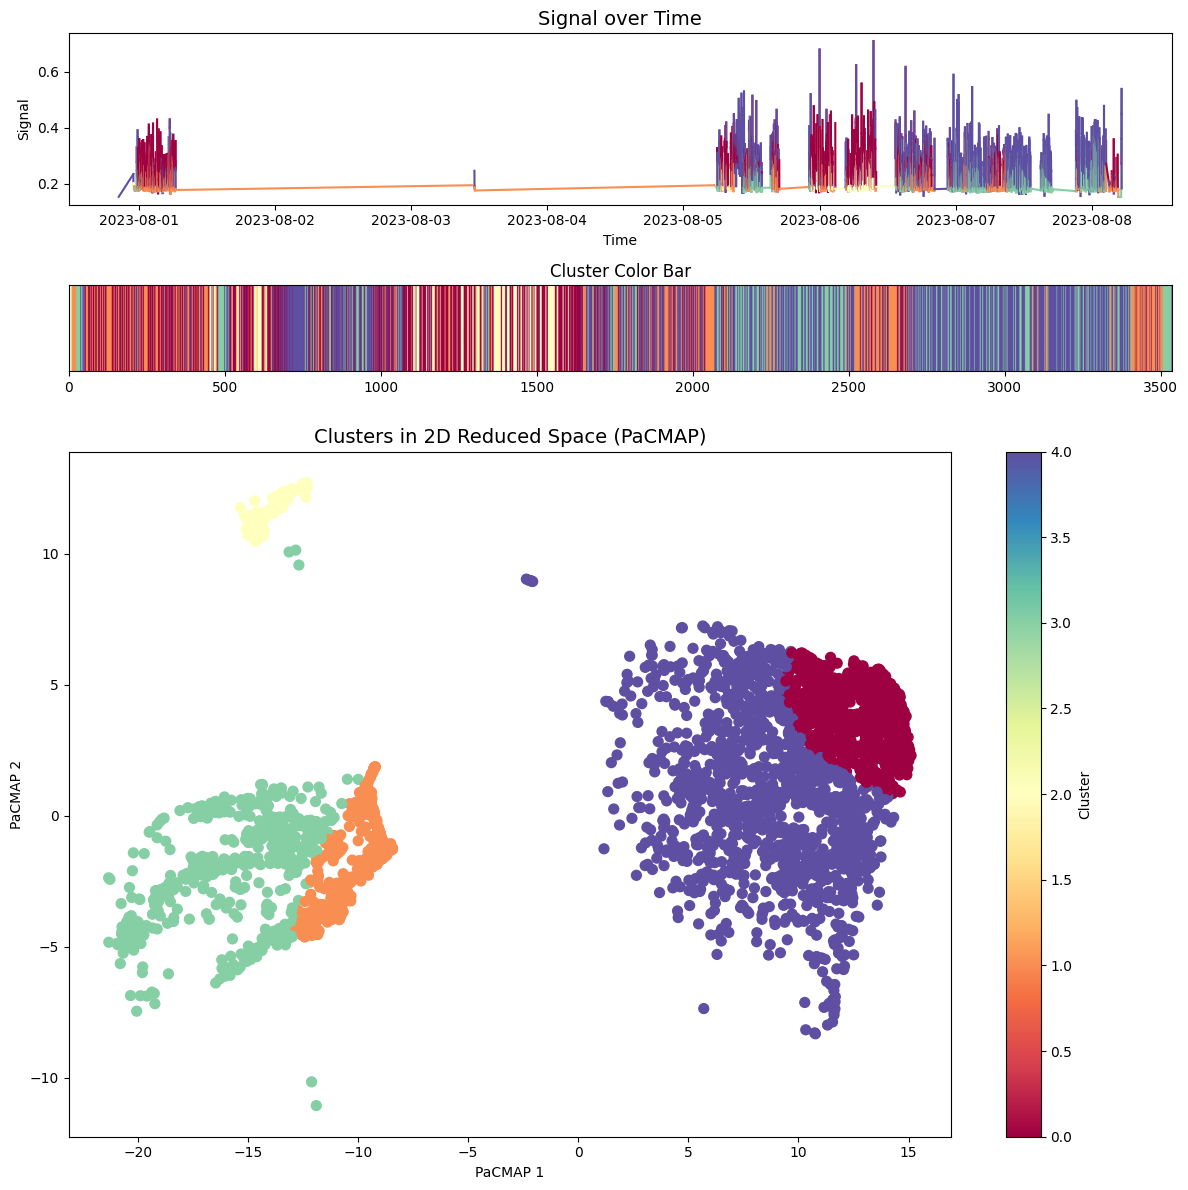

The MOF Bomba hidráulica con fuga


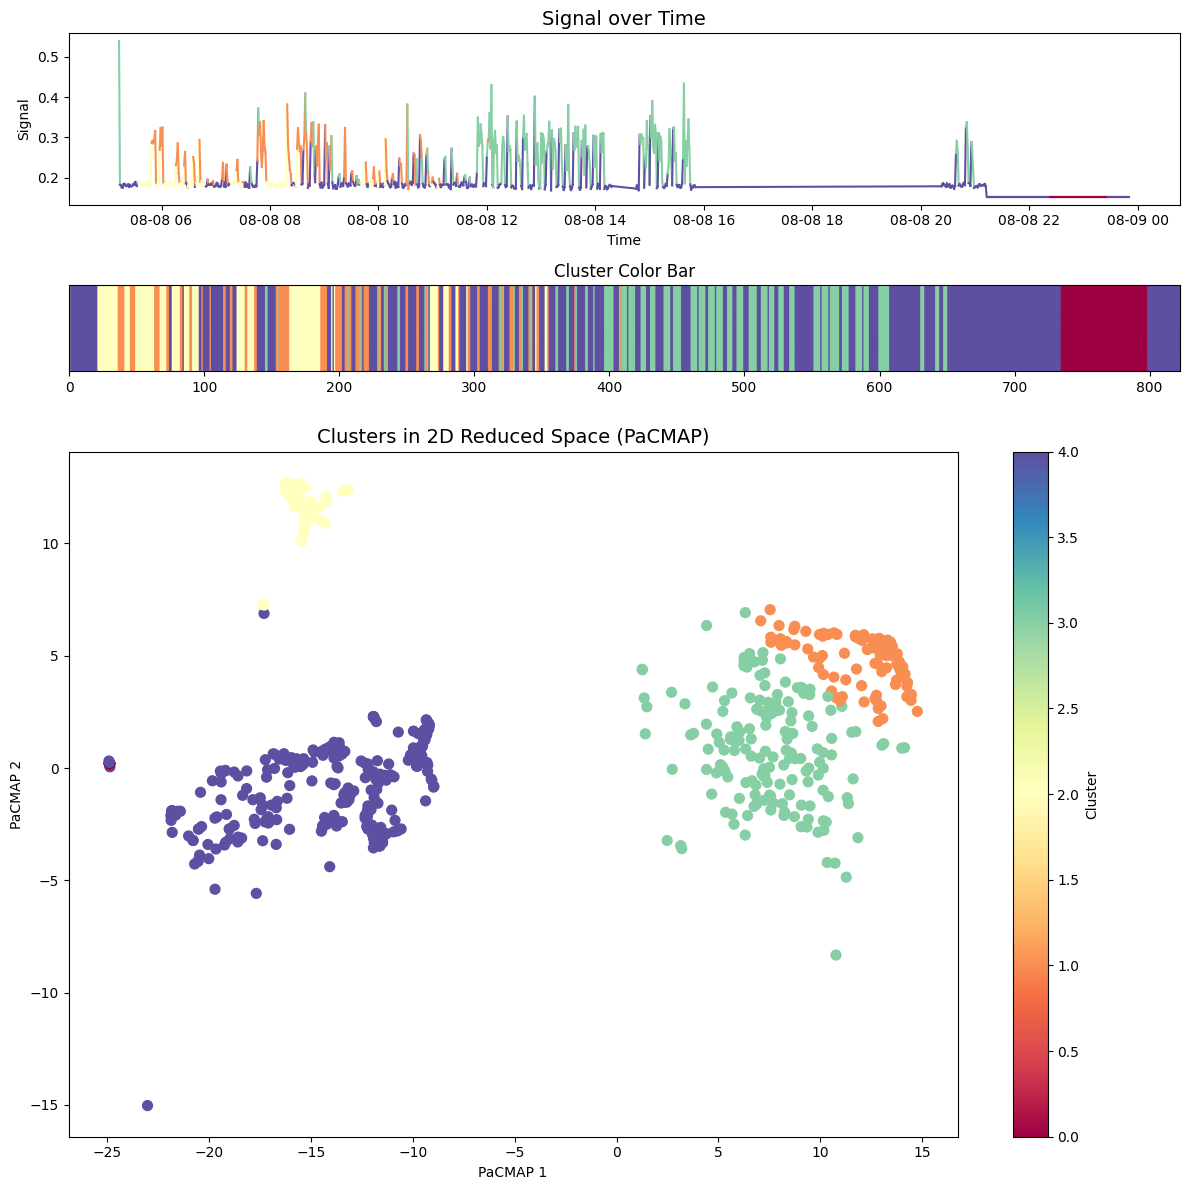

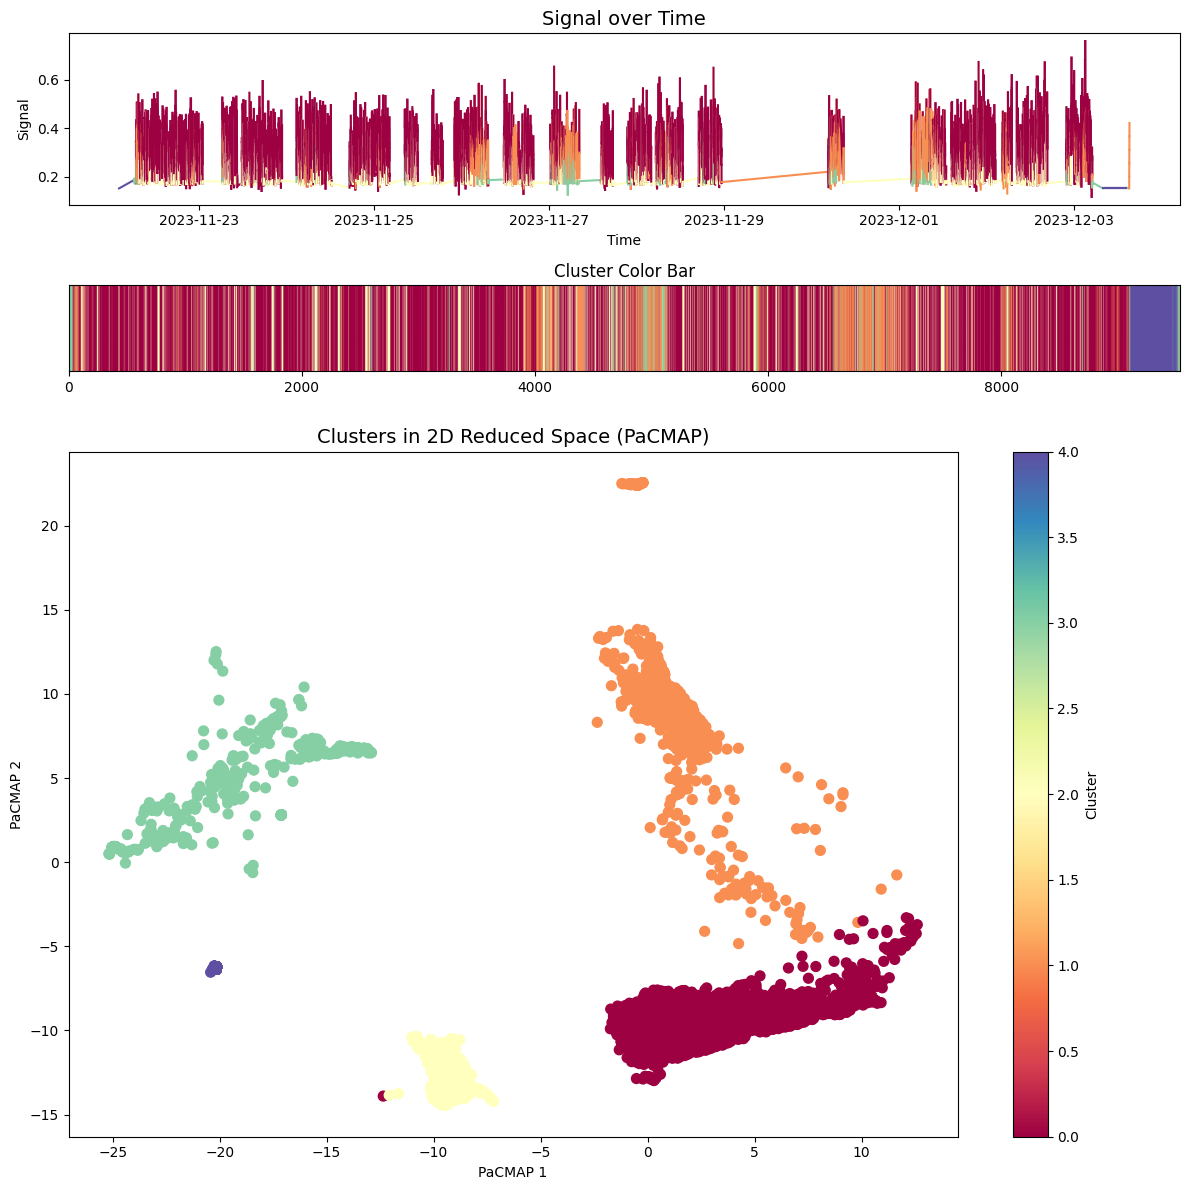

The MOF Fuga de aceite


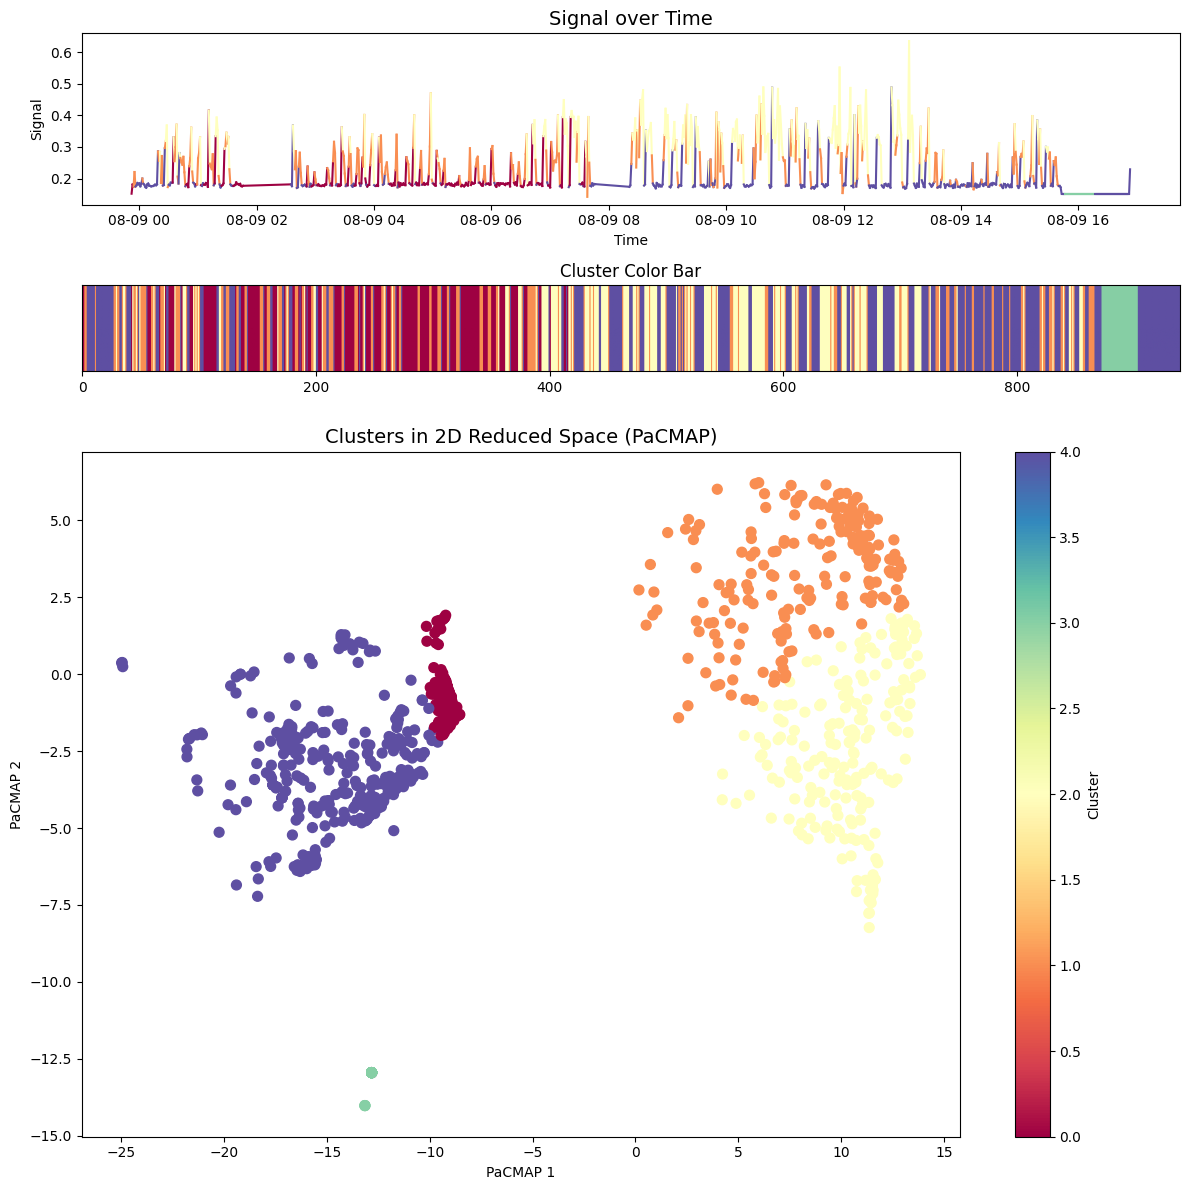

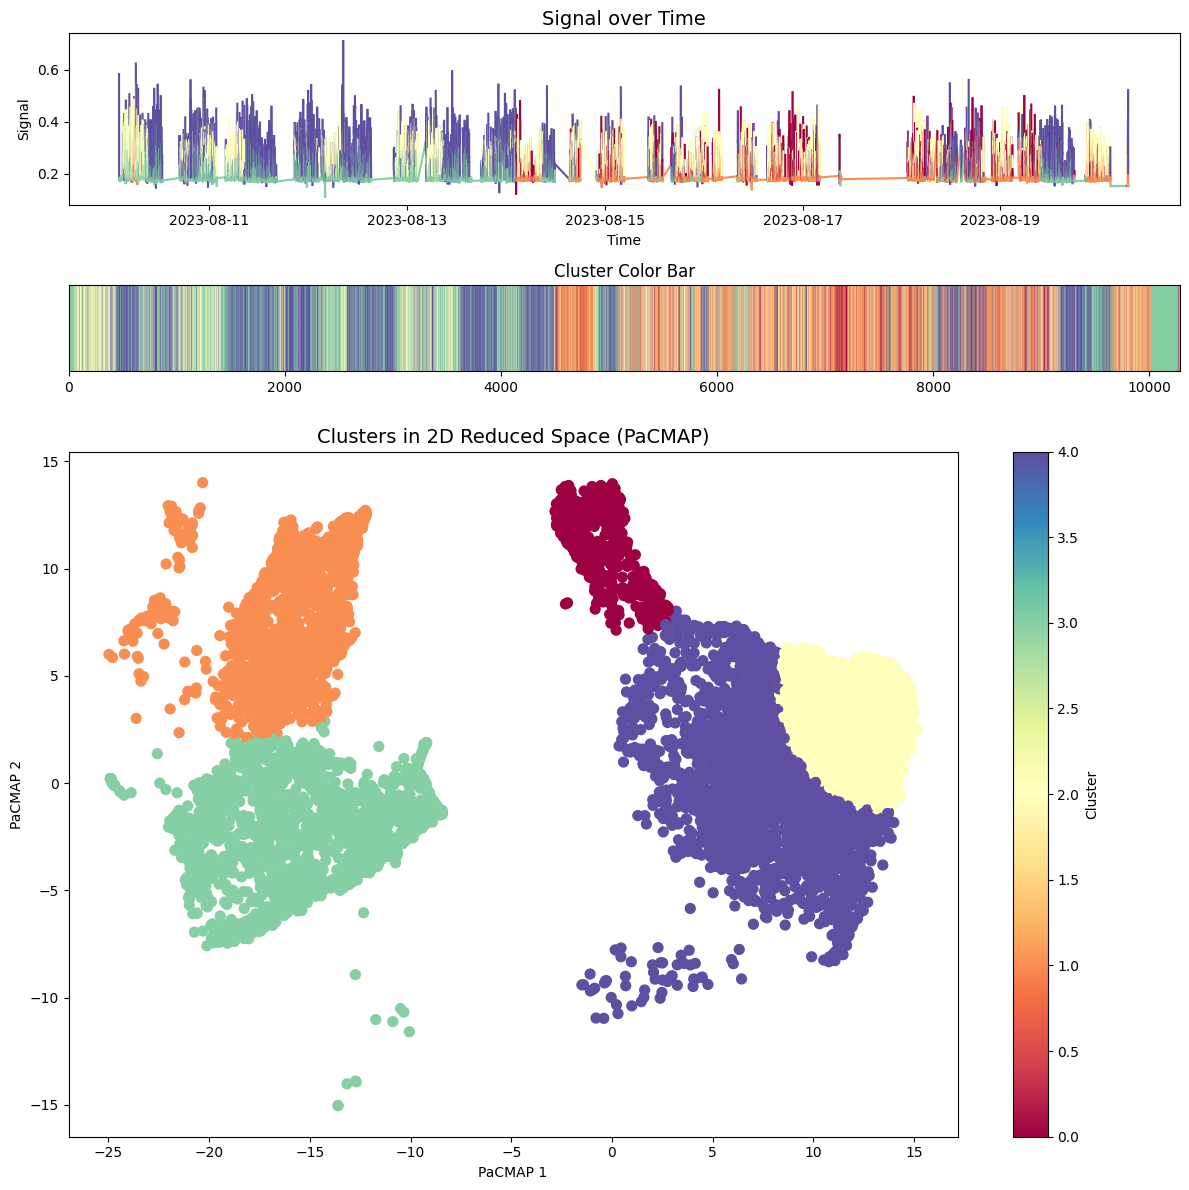

The MOF Falla sistema de hidroset-poste


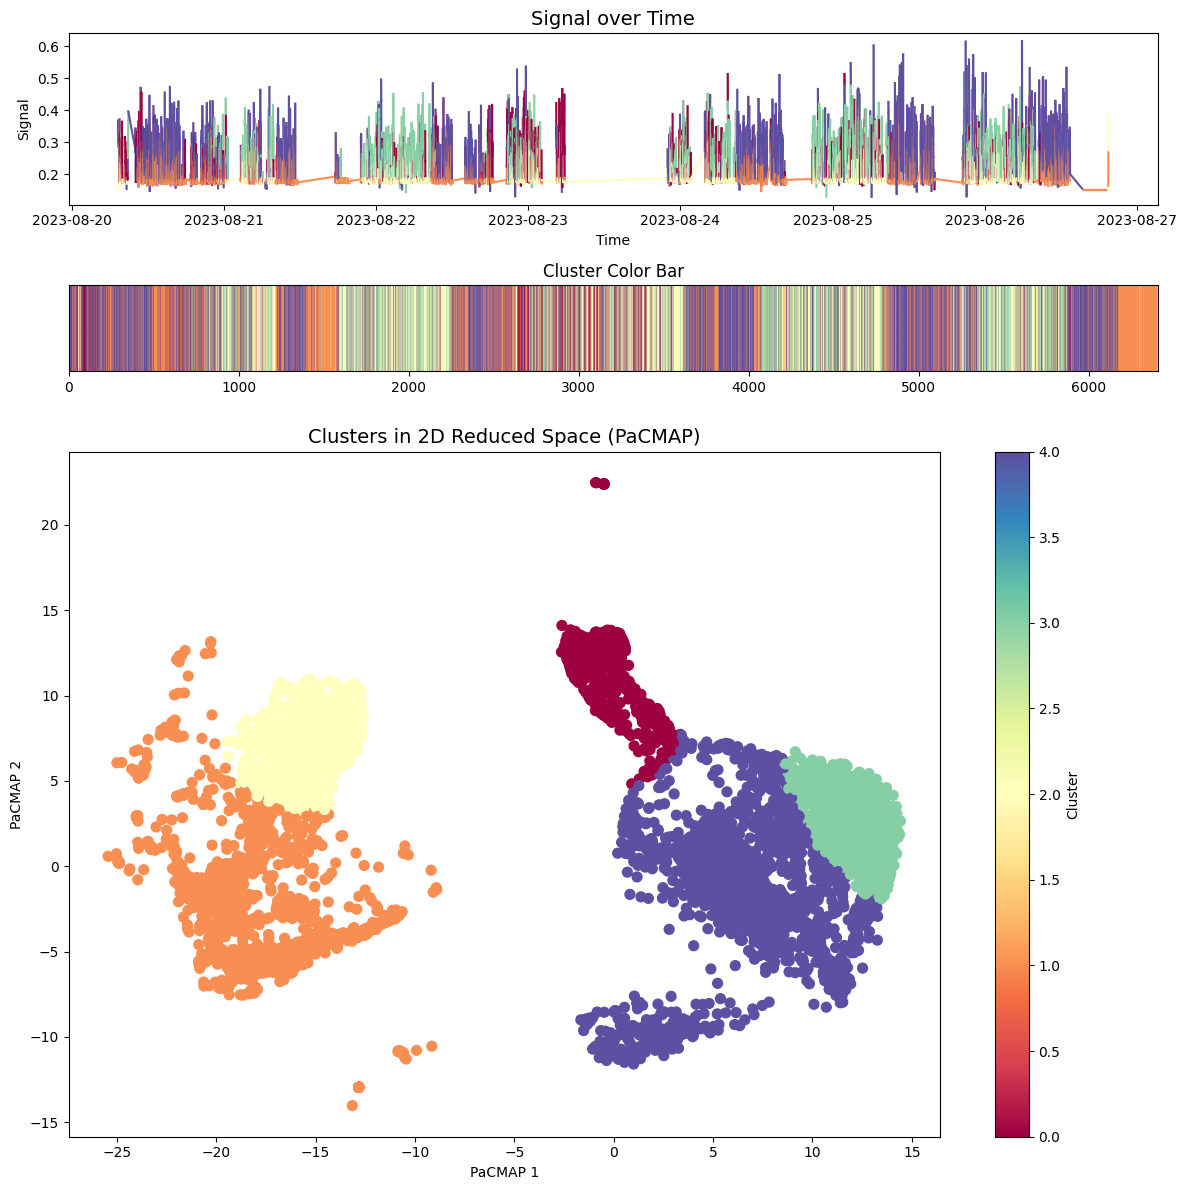

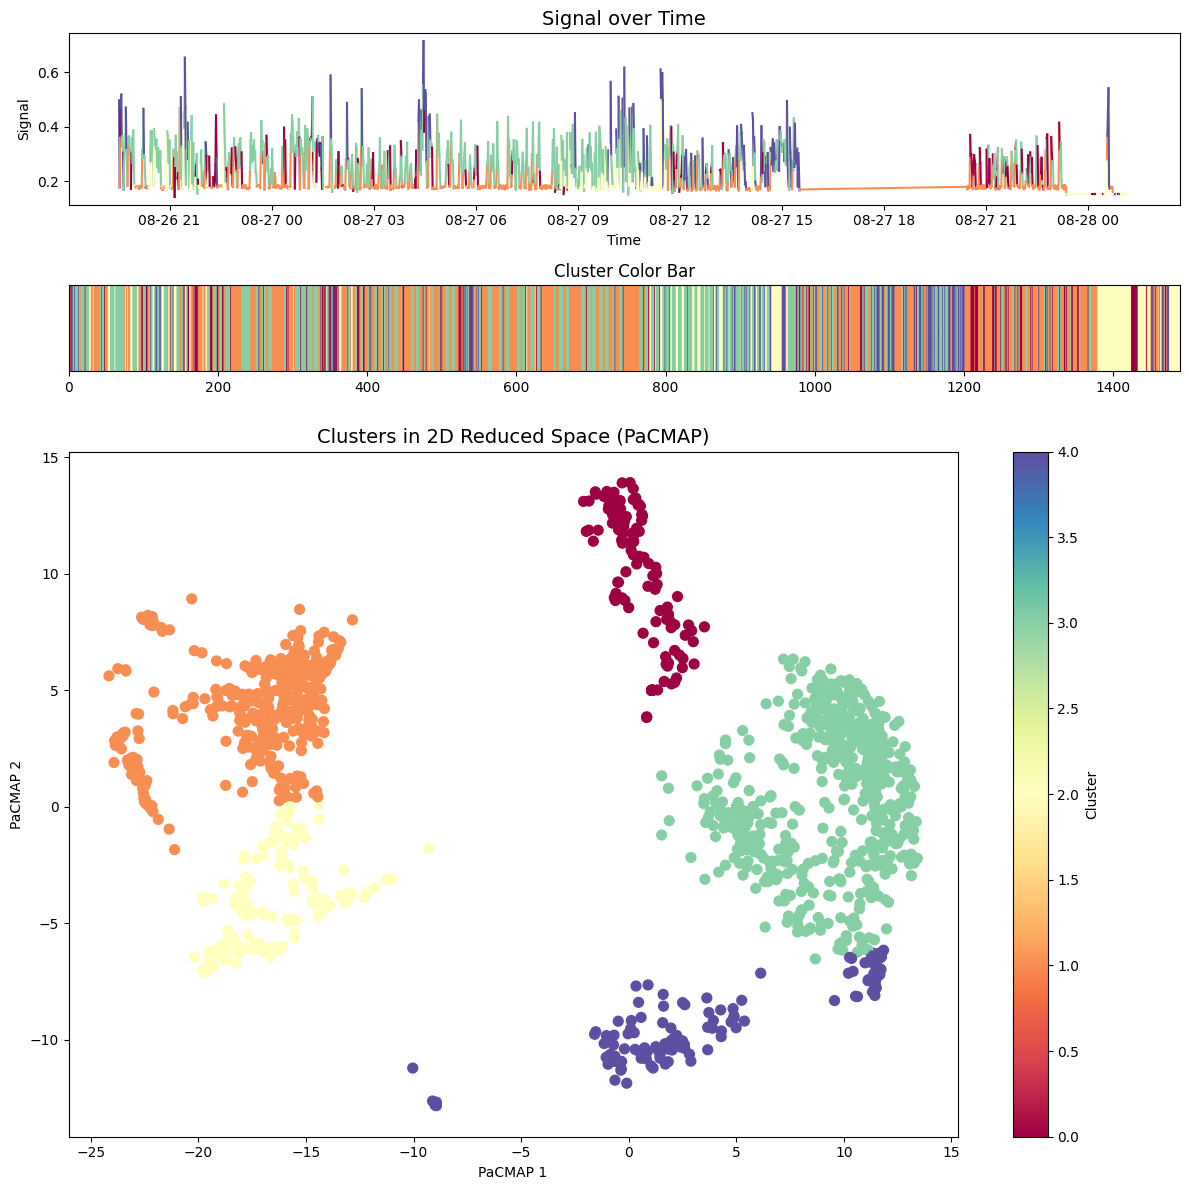

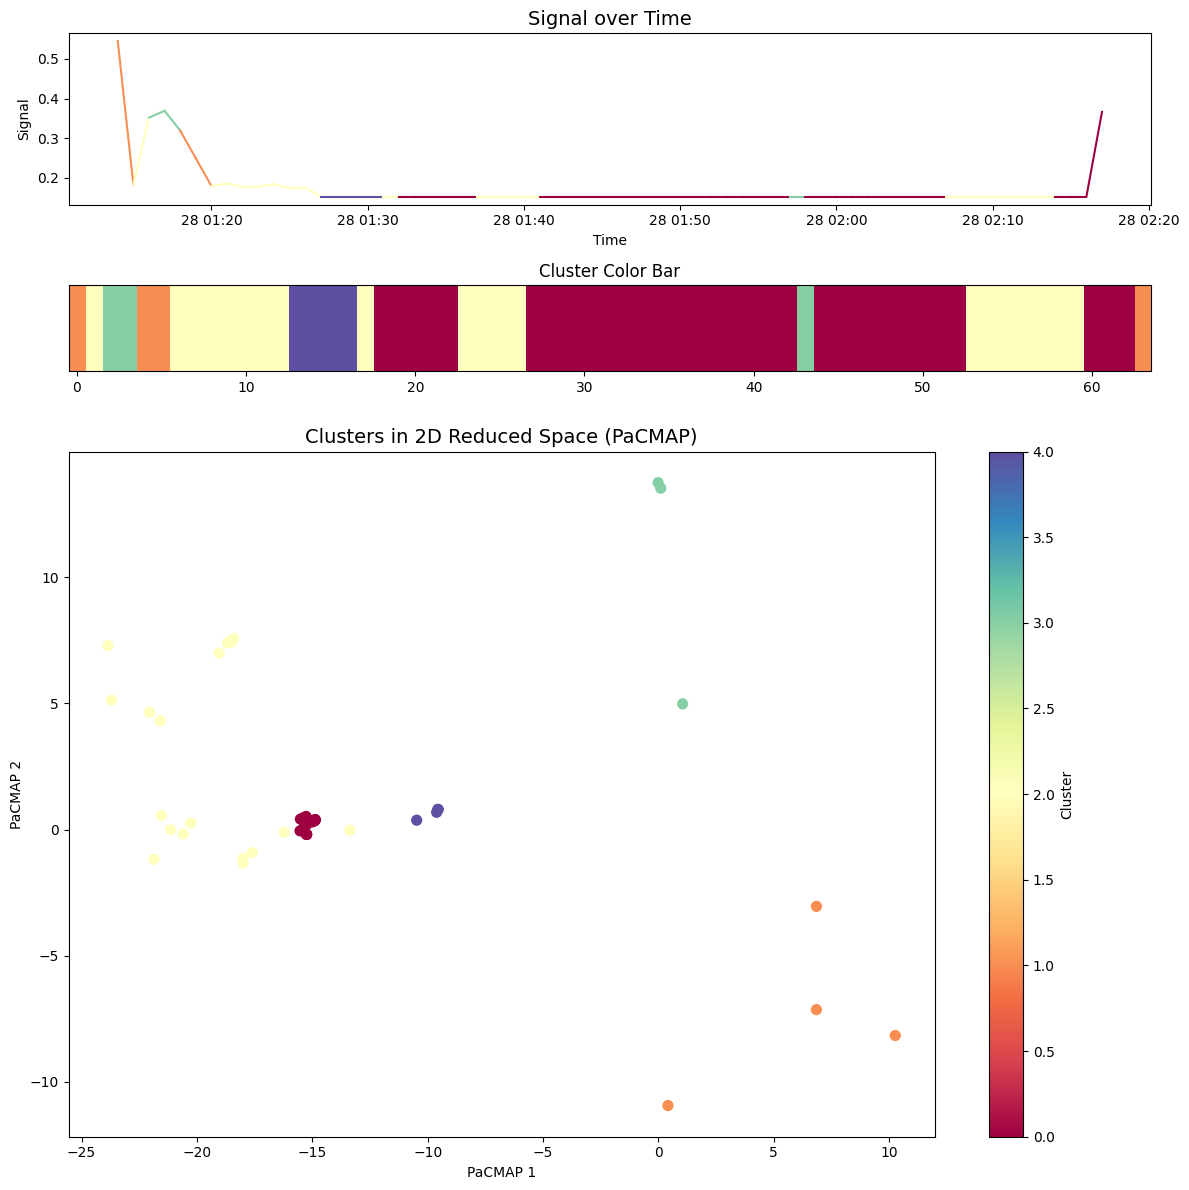

The MOF Mandibulas o revestimiento suelto


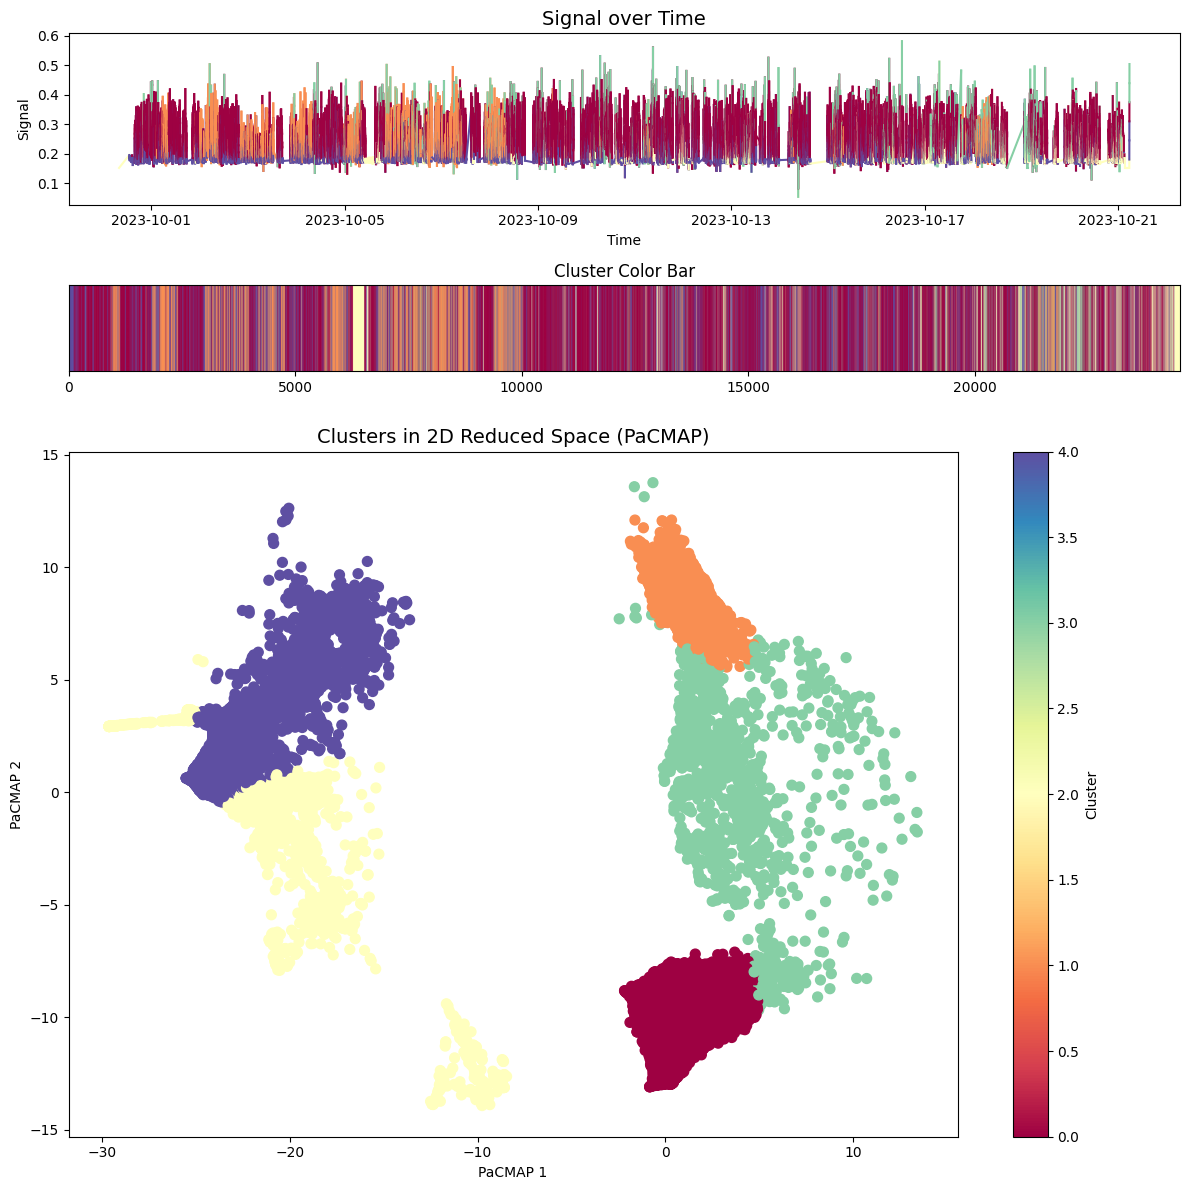

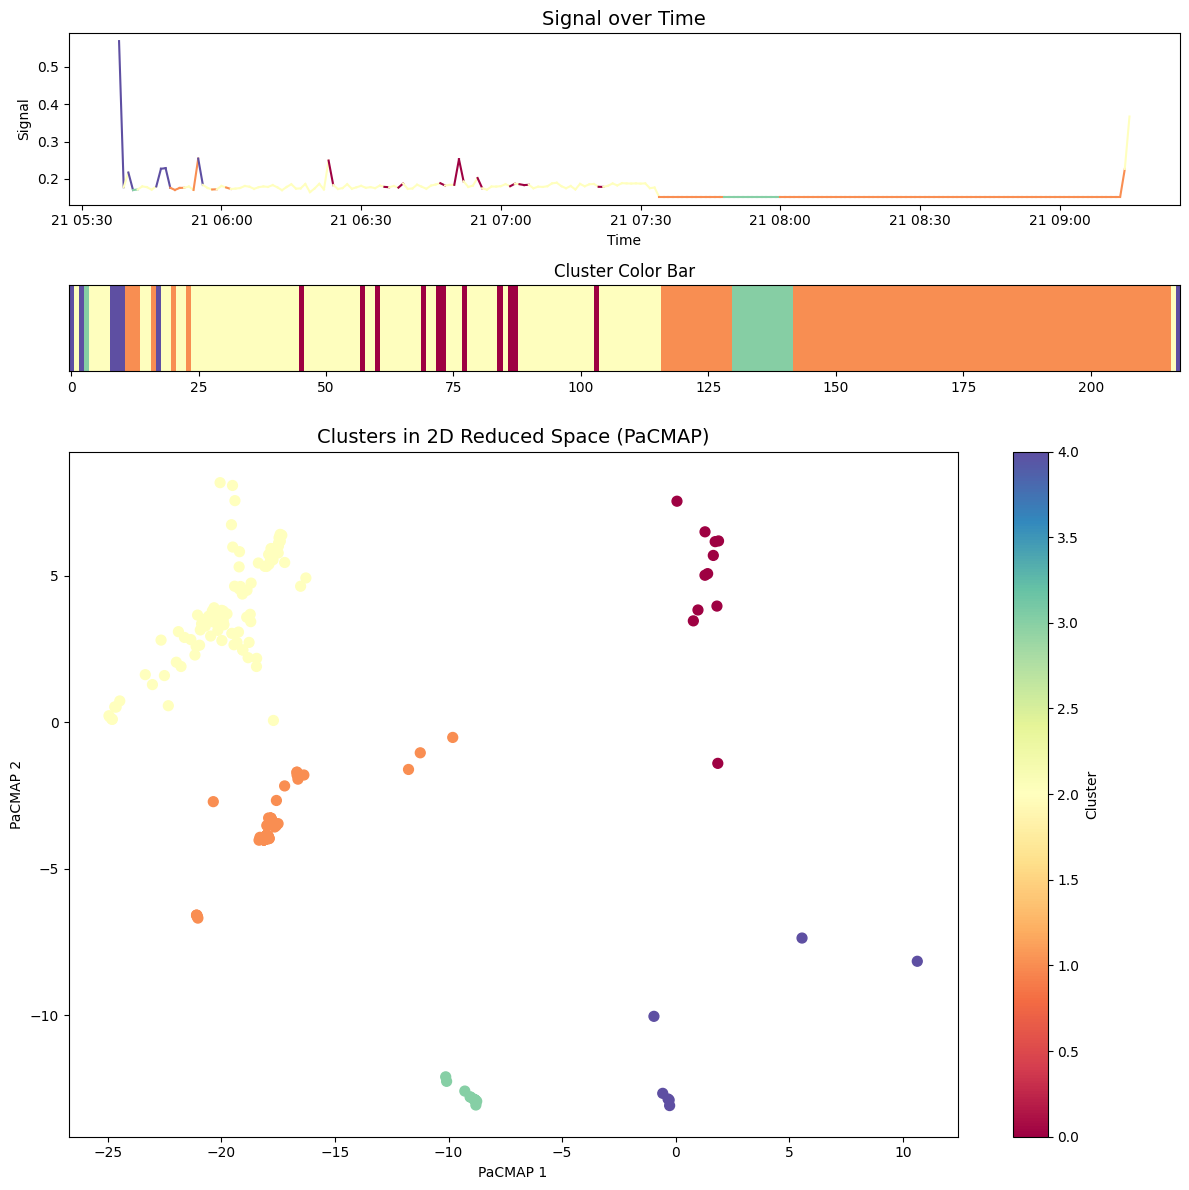

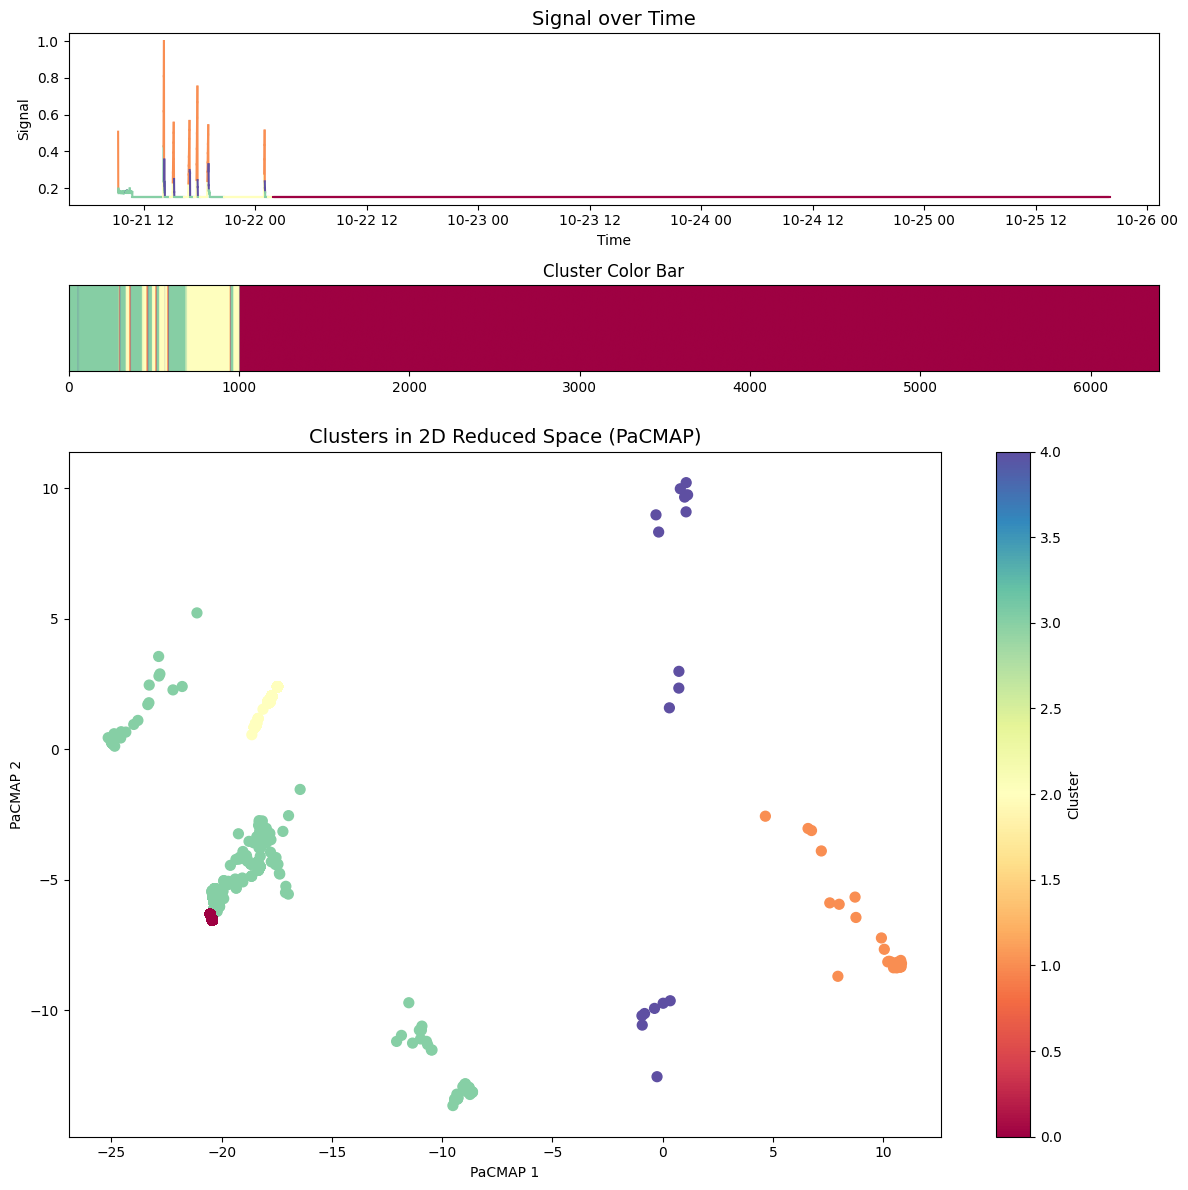

In [20]:
pacmapModel                 = pacmap.PaCMAP(    n_components = 2, 
                                                random_state = 40, 
                                                save_tree    = True)

clusterAlg                  = GaussianMixture(  n_components = 5, 
                                                random_state = 3, 
                                                n_init       = 5)

pacmapModel.fit(normalizedHealthy[preData.beauManipulatedCr1])            # Train with the healthy data

for mof, idxTrajectList in trajectory.items():
    print(f"The MOF {mof}")
    for idx,curTraject in enumerate(idxTrajectList):

        # -----------------------------
        # Transform the PACMAP
        # -----------------------------
        trajectVariables   = curTraject[preData.beauManipulatedCr1]     # Extract the 
        # print("--------------------")
        # print(efficiencyTraject.shape)
        embedding           = pacmapModel.transform(trajectVariables)
        dim1 = embedding[:, 0]  # First dimension from pacmap (size 100)
        dim2 = embedding[:, 1]  # Second dimension from pacmap (size 100)
        # print(embedding.shape)

        # -----------------------------
        # Cluster
        # -----------------------------
        clusters            = clusterAlg.fit_predict(embedding)
        # print(clusterRst.shape)
        
        # -----------------------------
        # Plot
        # -----------------------------
        testSignal = curTraject["Potencia(kW)"]
        time       = curTraject["tiempo"]

        norm = Normalize(vmin=clusters.min(), vmax=clusters.max())
        colors = plt.cm.Spectral(norm(clusters))  # Use the 'Spectral' colormap

        # Create subplots
        fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 12), gridspec_kw={'height_ratios': [1, 0.5, 4]})

        # Plot 1: Signal over time with color from cluster
        for i in range(len(testSignal) - 1):
            ax1.plot(time[i:i+2], testSignal[i:i+2], color=colors[i])  # Plot segments of the signal with cluster color

        ax1.set_title('Signal over Time', fontsize=14)
        ax1.set_xlabel('Time')
        ax1.set_ylabel('Signal')

        # Plot 2: Colorbar for clusters
        ax2.imshow([colors], aspect='auto')  # Display the color range horizontally
        ax2.set_yticks([])  # Remove y-axis ticks
        ax2.set_title('Cluster Color Bar')

        # Plot 3: Clusters in 2D Reduced Space (PaCMAP embedding)
        scatter = ax3.scatter(embedding[:, 0], embedding[:, 1], c=clusters, cmap='Spectral', s=50)
        ax3.set_title('Clusters in 2D Reduced Space (PaCMAP)', fontsize=14)
        ax3.set_xlabel('PaCMAP 1')
        ax3.set_ylabel('PaCMAP 2')

        # Add a colorbar for the clusters in the 2D space
        fig.colorbar(scatter, ax=ax3, label='Cluster')

        plt.tight_layout()
        plt.show()